# พยากรณ์ราคาไข่ไก่ล่วงหน้า 1 เดือน เพื่อวางแผนจัดซื้อเสบียง (SDG 2: Zero Hunger)
**เวอร์ชัน B · ราคา + ข้อมูลประกอบ (จำนวนแม่ไก่ไข่ USDA NASS + ไข้หวัดนก USDA APHIS)** แล้วเลือกเฉพาะกลุ่มตัวแปรที่ช่วยจริง (เวอร์ชันราคาอย่างเดียวอยู่ที่ `DS_Capstone_v2.ipynb`)

**โจทย์:** ทำนายราคาเฉลี่ยไข่ไก่ Grade A ขนาดใหญ่ (USD ต่อโหล) ของสหรัฐฯ (U.S. city average) **ล่วงหน้า 1 เดือน** โดยใช้ **ราคาย้อนหลังจาก BLS (`average_prices`)** เป็นหลัก และทดลองเพิ่ม **จำนวนแม่ไก่ไข่ (USDA NASS)** และ **ไก่ไข่ที่ติดไข้หวัดนก (USDA APHIS)** เป็นการทดลองแยก (B) เพื่อให้ฝ่ายจัดซื้อตั้งงบและตัดสินใจซื้อเสบียงเดือนหน้า

> ข้อมูลประกอบทั้งสองชุดดาวน์โหลดจากแหล่งทางการของ USDA โดยตรง และตรวจแล้วในขั้น 3 การเลือกตัวแปรทำบน *ช่วงคัดเลือก* แล้ววัดผลจริงบน *ช่วงประเมิน* ที่ไม่ได้ใช้เลือก (ขั้น 7)

## Workflow ของ notebook นี้ (รันจากบนลงล่างได้ทั้งไฟล์)

| ขั้น | ทำอะไร | ตรงกับข้อกำหนด |
|---|---|---|
| 0 | ตั้งค่า (import, ค่าคงที่) | – |
| 1 | ตั้งโจทย์ | **R1** |
| 2 | โหลดข้อมูลราคา BLS + แม่ไก่ไข่ NASS + ไข้หวัดนก APHIS | R2 |
| 3 | ตรวจและทำความสะอาดข้อมูล | **R2** |
| 4 | EDA เชิงวิเคราะห์ (ไม่ใช่แค่สถิติพรรณนา) | **R3** |
| 5 | สร้าง features + ตรวจ data leakage | R1/R2 |
| 6 | ตั้งวิธีประเมิน (walk-forward, MAE, MASE) | R1/R4 |
| 7 | สร้างโมเดลเทียบ baseline + เทียบ/เลือกกลุ่มตัวแปร | **R4** |
| 8 | วิเคราะห์ว่าโมเดลพลาดตรงไหน | **R5** |
| 9 | สรุปตัวเลขสำหรับโปสเตอร์ + ข้อเสนอแนะ | **R6** |
| 10 | บันทึกการใช้ AI | **R7** |

> หลักของ notebook: **1 cell = 1 งาน** และทุก cell ที่ได้ข้อสรุปจะ *คำนวณข้อสรุปจากข้อมูล* แล้ว print ออกมา ไม่พิมพ์ข้อความตายตัว ตัวเลขบนโปสเตอร์จึงตรงกับ notebook เสมอ

## ขั้น 0 · ตั้งค่า

In [ ]:
# 0.1 import library ทั้งหมดไว้ที่เดียว
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.figsize': (12, 4.5), 'axes.grid': True, 'grid.alpha': 0.3})
# หมายเหตุ: ชื่อแกน/legend ในกราฟใช้ภาษาอังกฤษ เพราะฟอนต์ใน Colab ไม่มีภาษาไทย

In [ ]:
# 0.2 ค่าคงที่ที่ใช้ทั้ง notebook (อยากเปลี่ยนการทดลอง แก้ตรงนี้ที่เดียว)
DATA_DIR    = 'data'
ITEM_PREFIX = 'Eggs, grade A, large'   # ไข่ Grade A ขนาดใหญ่ ต่อโหล
AREA        = 'U.S. city average'      # ค่าเฉลี่ยทั้งสหรัฐฯ (ไม่แยกเมือง/ภูมิภาค)
TEST_START  = '2019-01-01'             # ทดสอบตั้งแต่ 2019 → ล่าสุด (มีทั้งช่วงปกติและช่วงราคาพุ่ง 2022-2025)
SPIKE       = 0.10                     # นิยาม "ราคาพุ่ง" = เดือนหน้าขึ้นเกิน 10%
WARN        = 0.05                     # โมเดล "เตือน" ถ้าทายว่าจะขึ้นเกิน 5%
VOL_Q       = 0.75                     # นิยาม "ช่วงผันผวน" = ความผันผวน 6 เดือนล่าสุดสูงกว่า percentile ที่ 75 ของช่วง train
SEED        = 42
LAYERS_FILE = 'nass_layers.csv'          # จำนวนแม่ไก่ไข่รายเดือน USDA NASS (2007-12 → 2025-12)
HPAI_FILE   = 'hpai_flocks.csv'          # ฟาร์มที่ติดไข้หวัดนก USDA APHIS (2022-02 → 2026-11), 1 แถว = 1 ฟาร์ม
TEST_B_START = '2022-06-01'             # การทดลอง B เริ่มทดสอบหลังข้อมูลไข้หวัดนกเริ่ม 4 เดือน
SELECT_END   = '2024-05-01'             # ช่วงคัดเลือกตัวแปร: TEST_B_START → SELECT_END | ช่วงประเมิน: หลังจากนั้น
MIN_GAIN     = 0.02                     # จะเก็บกลุ่มตัวแปรไว้ถ้าทำให้ MASE ในช่วงคัดเลือกดีขึ้นอย่างน้อยเท่านี้
LAYERS_LAG  = 1                          # NASS ประกาศตัวเลขเดือน t ราวปลายเดือน t+1 → ใช้ช้ากว่าราคา 1 เดือนเพื่อไม่ให้ leak

## ขั้น 1 · ตั้งโจทย์ (R1)
*(ร่างให้แล้ว กลุ่มปรับถ้อยคำได้ แต่ต้องตอบครบ 5 ข้อ)*

1. **ใครใช้ ใช้ตัดสินใจอะไร:** ฝ่ายจัดซื้อเสบียงที่ซื้อไข่เป็นประจำ (เช่น โรงอาหาร/โครงการอาหารกลางวัน, food bank, ร้านอาหาร) ใช้ราคาที่ทายได้ **ตั้งงบซื้อไข่เดือนหน้า** และตัดสินใจว่า *ควรซื้อตุนเดือนนี้ / ซื้อตามปกติ / ลดปริมาณหรือหาโปรตีนทดแทน*
2. **ทำนายเมื่อไร ข้อมูลมีจริงไหม:** ทำนายราคาเดือน t+1 โดยใช้ราคาถึงเดือน t เท่านั้น
   - จำนวนแม่ไก่ไข่: NASS ประกาศเดือน t ราวปลายเดือน t+1 จึงใช้ตัวเลขถึงเดือน t-1 เท่านั้น
   - ไข้หวัดนก: APHIS ประกาศฟาร์มที่ติดเชื้อภายในไม่กี่วัน จึงใช้ยอดถึงสิ้นเดือน t ได้
   - ข้อจำกัดที่ต้องบอก: BLS ประกาศราคาเดือน t ประมาณกลางเดือน t+1 ดังนั้นในทางปฏิบัติ ผลทายจะพร้อมใช้ราวกลางเดือน t+1 (ใช้ปรับงบครึ่งเดือนหลัง และเป็นสัญญาณสำหรับรอบสั่งซื้อถัดไป)
3. **Attribute:** 1 แถว = 1 เดือน × ราคาเฉลี่ยทั้งสหรัฐฯ (USD/โหล) จาก BLS series `APU0000708111` (ปี 1980 → 2026) + จำนวนแม่ไก่ไข่เฉลี่ยของเดือน (ตัว) จาก USDA NASS (2007-12 → 2025-12) + ฟาร์มที่ติดไข้หวัดนก (วันที่ × รัฐ × ประเภทฟาร์ม × จำนวนนก) จาก USDA APHIS (2022-02 → 2026-11)
4. **เป้าหมาย:** ราคาเฉลี่ยไข่ไก่ Grade A ขนาดใหญ่ 1 โหล (U.S. city average) ของเดือนถัดไป
5. **ความผิดพลาดแบบไหนแพงกว่า:** *ทายต่ำไปตอนราคากำลังพุ่ง* แพงกว่า (งบไม่พอ ต้องซื้อแพงฉุกเฉิน) จึงใช้
   - **MAE** (USD/โหล) อ่านเข้าใจง่ายสำหรับฝ่ายจัดซื้อ = งบที่คลาดเคลื่อนต่อโหล
   - **MASE** = MAE โมเดล ÷ MAE baseline (< 1 = ชนะ baseline ที่ฝ่ายจัดซื้อใช้อยู่แล้วโดยไม่ต้องมีโมเดล)
   - **Spike recall** = เดือนที่ราคาพุ่งเกิน 10% จริง โมเดลเตือนทันกี่ครั้ง

## ขั้น 2 · โหลดข้อมูล

In [ ]:
# 2.1 โหลดราคาสินค้า BLS (ใช้ parquet เพราะเล็กกว่า csv 50 เท่า)
def load_prices():
    for name in ['average_prices.parquet', 'average_prices.csv']:
        for path in [os.path.join(DATA_DIR, name), name]:
            if os.path.exists(path):
                print('โหลดจาก', path)
                return pd.read_parquet(path) if path.endswith('.parquet') else pd.read_csv(path, low_memory=False)
    from google.colab import files          # ถ้าไม่เจอไฟล์ ให้อัปโหลดใน Colab
    print('ไม่พบไฟล์ กรุณาอัปโหลด average_prices.parquet')
    name = list(files.upload())[0]
    return pd.read_parquet(name) if name.endswith('.parquet') else pd.read_csv(name, low_memory=False)

def find_or_upload(fname):
    """หาไฟล์ใน data/ หรือโฟลเดอร์ปัจจุบัน ถ้าไม่เจอ (เช่นเปิดใน Colab ครั้งแรก) ให้อัปโหลด"""
    for path in [os.path.join(DATA_DIR, fname), fname]:
        if os.path.exists(path):
            return path
    from google.colab import files
    print(f'ไม่พบ {fname} กรุณาอัปโหลดไฟล์นี้')
    uploaded = files.upload()
    assert fname in uploaded, f'ต้องอัปโหลดไฟล์ชื่อ {fname}'
    return fname

raw = load_prices()
print(f'ข้อมูลทั้งหมด: {len(raw):,} แถว × {raw.shape[1]} คอลัมน์ | สินค้า {raw.item_name.nunique()} รายการ | พื้นที่ {raw.area_name.nunique()} แห่ง')
raw.head(3)

โหลดจาก data/average_prices.parquet


ข้อมูลทั้งหมด: 356,549 แถว × 14 คอลัมน์ | สินค้า 160 รายการ | พื้นที่ 74 แห่ง


,series_id,date,year,month,item_code,item_name,category,area_code,area_name,area_type,price_usd,unit,seasonally_adjusted,footnote_code
0,APU0000701111,1980-01-01,1980,1,701111,"Flour, white, all purpose, per lb. (453.6 gm)",food,0000,U.S. city average,national,0.203,pound,False,NaN
1,APU0000701111,1980-02-01,1980,2,701111,"Flour, white, all purpose, per lb. (453.6 gm)",food,0000,U.S. city average,national,0.205,pound,False,NaN
2,APU0000701111,1980-03-01,1980,3,701111,"Flour, white, all purpose, per lb. (453.6 gm)",food,0000,U.S. city average,national,0.211,pound,False,NaN


In [ ]:
# 2.2 กรองเฉพาะไข่ไก่ ค่าเฉลี่ยทั้งประเทศ
eggs_raw = raw[raw['item_name'].str.startswith(ITEM_PREFIX) & (raw['area_name'] == AREA)].copy()
eggs_raw['date'] = pd.to_datetime(eggs_raw['date'])
eggs_raw = eggs_raw.sort_values('date').reset_index(drop=True)

print('series_id :', eggs_raw['series_id'].unique())
print('ช่วงเวลา   :', eggs_raw['date'].min().date(), '→', eggs_raw['date'].max().date())
print('จำนวนแถว   :', len(eggs_raw), 'เดือน')
eggs_raw[['date', 'price_usd', 'footnote_code']].tail()

series_id : <ArrowStringArray>
['APU0000708111']
Length: 1, dtype: str
ช่วงเวลา   : 1980-01-01 → 2026-09-01
จำนวนแถว   : 561 เดือน


,date,price_usd,footnote_code
556,2026-05-01,2.191,NaN
557,2026-06-01,2.141,NaN
558,2026-07-01,2.189,NaN
559,2026-08-01,2.272,NaN
560,2026-09-01,2.272,NaN


In [ ]:
# 2.3 โหลดจำนวนแม่ไก่ไข่รายเดือน (USDA NASS Quick Stats: Survey > Animals & Products > Poultry > Chickens > Inventory, avg, National, Monthly)
LAYERS_ITEM = 'CHICKENS, LAYERS, TABLE - INVENTORY, AVG, MEASURED IN HEAD'
lay_path = find_or_upload(LAYERS_FILE)
layers_raw = pd.read_csv(lay_path)
print('โหลดจาก', lay_path, '|', f'{len(layers_raw):,} แถว')
layers_raw[['Year', 'Period', 'Data Item', 'Domain', 'Value']].head()

โหลดจาก data/nass_layers.csv | 1,302 แถว


,Year,Period,Data Item,Domain,Value
0,2025,APR,"CHICKENS, LAYERS - INVENTORY, AVG, MEASURED IN...",TOTAL,"358,756,000"
1,2025,APR,"CHICKENS, LAYERS, HATCHING - INVENTORY, AVG, M...",TOTAL,"64,511,000"
2,2025,APR,"CHICKENS, LAYERS, HATCHING, BROILER TYPE - INV...",TOTAL,"60,580,000"
3,2025,APR,"CHICKENS, LAYERS, HATCHING, EGG TYPE - INVENTO...",TOTAL,"3,931,000"
4,2025,APR,"CHICKENS, LAYERS, TABLE - INVENTORY, AVG, MEAS...","INVENTORY OF LAYERS, TABLE","281,158,000"


In [ ]:
# 2.4 โหลดข้อมูลฟาร์มที่ติดไข้หวัดนก (USDA APHIS dashboard > sheet ExportToCsv)
# ที่มา: https://publicdashboards.dl.usda.gov/t/MRP_PUB/views/VS_Avian_HPAIConfirmedDetections2022/ExportToCsv.csv
hpai_path = find_or_upload(HPAI_FILE)
hpai_raw = pd.read_csv(hpai_path)
print('โหลดจาก', hpai_path, '|', f'{len(hpai_raw):,} แถว (1 แถว = 1 ฟาร์มที่ยืนยันผล) | คอลัมน์:', list(hpai_raw.columns))
hpai_raw.head(3)

โหลดจาก data/hpai_flocks.csv | 2,307 แถว (1 แถว = 1 ฟาร์มที่ยืนยันผล) | คอลัมน์: ['Confirmed Diagnosis', 'Control Area Released', 'County Name', 'Production', 'Special ID', 'State', 'Birds Affected (Table)', 'Min. Confirmed Diagnosis']


,Confirmed Diagnosis,Control Area Released,County Name,Production,Special ID,State,Birds Affected (Table),Min. Confirmed Diagnosis
0,2022-02-08,2022-03-23,Dubois,Commercial Turkey Meat Bird,Dubois 01,Indiana,"29,000",2022-02-08
1,2022-02-12,2022-03-15,Fulton,Commercial Broiler Production,Fulton 01,Kentucky,"231,400",2022-02-12
2,2022-02-12,2022-02-27,Fauquier,WOAH Non-Poultry,Fauquier 01,Virginia,90,2022-02-12


## ขั้น 3 · ตรวจและทำความสะอาดข้อมูล (R2)
ตรวจ 3 เรื่อง: เดือนหายไหม, ราคาว่างไหม, แถวซ้ำไหม แล้วแสดงให้เห็นว่าโค้ดเดิม (`shift` + `dropna`) ทำให้ข้อมูลเพี้ยนอย่างไร

In [ ]:
# 3.1 ตรวจคุณภาพข้อมูลราคา
full_months  = pd.date_range(eggs_raw['date'].min(), eggs_raw['date'].max(), freq='MS')
missing_rows = full_months.difference(eggs_raw['date'])
na_rows      = eggs_raw[eggs_raw['price_usd'].isna()]

print('เดือนที่ไม่มีแถวเลย        :', len(missing_rows))
print('แถวซ้ำ (วันที่ซ้ำ)           :', eggs_raw['date'].duplicated().sum())
print('เดือนที่มีแถวแต่ราคาว่าง    :', len(na_rows))
na_rows[['date', 'price_usd', 'footnote_code']]

เดือนที่ไม่มีแถวเลย        : 0
แถวซ้ำ (วันที่ซ้ำ)           : 0
เดือนที่มีแถวแต่ราคาว่าง    : 1


,date,price_usd,footnote_code
549,2025-10-01,NaN,X


In [ ]:
# 3.2 ปัญหาของโค้ดเดิม: shift() เลื่อนตาม "แถว" แล้ว dropna() ลบเดือนรอบๆ ค่าว่างทิ้ง
old = eggs_raw[['date', 'price_usd']].copy()
for k in [1, 2, 3, 12]:
    old[f'lag_{k}'] = old['price_usd'].shift(k)
old_clean = old.dropna()
lost = sorted(set(eggs_raw['date']) - set(old_clean['date']))
lost_recent = [d.strftime('%Y-%m') for d in lost if d.year >= 2000]
print(f'วิธีเดิมลบข้อมูลทิ้ง {len(lost)} เดือน ในนั้นเป็นช่วงล่าสุด: {lost_recent}')
print('→ test set เดิมจึงไม่ใช่เดือนต่อเนื่อง และกราฟลากเส้นข้ามช่วงที่หายไป')

วิธีเดิมลบข้อมูลทิ้ง 16 เดือน ในนั้นเป็นช่วงล่าสุด: ['2025-10', '2025-11', '2025-12', '2026-01']
→ test set เดิมจึงไม่ใช่เดือนต่อเนื่อง และกราฟลากเส้นข้ามช่วงที่หายไป


In [ ]:
# 3.3 แก้: บังคับให้มีครบทุกเดือน (asfreq) แล้วเติมเดือนที่ว่างด้วยการ interpolate เชิงเส้น
price = eggs_raw.set_index('date')['price_usd'].asfreq('MS')
imputed_months = price.index[price.isna()]
price = price.interpolate(method='linear')

for d in imputed_months:
    print(f'เติมค่า {d:%Y-%m} = ${price[d]:.3f} (ค่ากลางระหว่างเดือนก่อนและเดือนหลัง)')
print('ตอนนี้มี', len(price), 'เดือนติดกัน, ค่าว่าง =', price.isna().sum())

เติมค่า 2025-10 = $3.174 (ค่ากลางระหว่างเดือนก่อนและเดือนหลัง)
ตอนนี้มี 561 เดือนติดกัน, ค่าว่าง = 0


In [ ]:
# 3.4 ตรวจข้อมูลแม่ไก่ไข่: เลือกชุดที่ใช้ แล้วเช็กเดือนขาด/ซ้ำ
MONTHS = {m: k for k, m in enumerate(['JAN','FEB','MAR','APR','MAY','JUN','JUL','AUG','SEP','OCT','NOV','DEC'], 1)}
print('Data Item ในไฟล์:', layers_raw['Data Item'].value_counts().to_dict())
lay = layers_raw[(layers_raw['Data Item'] == LAYERS_ITEM) & (layers_raw['Domain'] == 'TOTAL')].copy()
lay['date']  = pd.to_datetime(dict(year=lay['Year'], month=lay['Period'].map(MONTHS), day=1))
lay['value'] = pd.to_numeric(lay['Value'].astype(str).str.replace(',', ''), errors='coerce')
layers = lay.set_index('date')['value'].sort_index()
missing = pd.date_range(layers.index[0], layers.index[-1], freq='MS').difference(layers.index)
print(f'ใช้: {LAYERS_ITEM} | {len(layers)} เดือน ({layers.index[0]:%Y-%m} → {layers.index[-1]:%Y-%m})')
print('เดือนขาด:', len(missing), '| เดือนซ้ำ:', layers.index.duplicated().sum(), '| ค่าว่าง:', layers.isna().sum())

Data Item ในไฟล์: {'CHICKENS, LAYERS, TABLE - INVENTORY, AVG, MEASURED IN HEAD': 434, 'CHICKENS, LAYERS - INVENTORY, AVG, MEASURED IN HEAD': 217, 'CHICKENS, LAYERS, HATCHING - INVENTORY, AVG, MEASURED IN HEAD': 217, 'CHICKENS, LAYERS, HATCHING, BROILER TYPE - INVENTORY, AVG, MEASURED IN HEAD': 217, 'CHICKENS, LAYERS, HATCHING, EGG TYPE - INVENTORY, AVG, MEASURED IN HEAD': 217}
ใช้: CHICKENS, LAYERS, TABLE - INVENTORY, AVG, MEASURED IN HEAD | 217 เดือน (2007-12 → 2025-12)
เดือนขาด: 0 | เดือนซ้ำ: 0 | ค่าว่าง: 0


In [ ]:
# 3.5 ตรวจความสมเหตุสมผล: จำนวนแม่ไก่ช่วงที่รู้ว่ามีการระบาด ต้องลดลงจริง
check = layers.loc[['2015-03-01', '2015-06-01', '2022-01-01', '2022-06-01', '2024-12-01', '2025-03-01']] / 1e6
print((check.round(1).astype(str) + ' ล้านตัว').to_string())

date
2015-03-01    313.1 ล้านตัว
2015-06-01    280.4 ล้านตัว
2022-01-01    329.4 ล้านตัว
2022-06-01    303.3 ล้านตัว
2024-12-01    312.8 ล้านตัว
2025-03-01    292.4 ล้านตัว


In [ ]:
# 3.6 ข้อมูลไข้หวัดนกรายฟาร์ม → "ไก่ไข่ที่ติดเชื้อต่อเดือน" (ล้านตัว)
hp = hpai_raw.copy()
hp['date']  = pd.to_datetime(hp['Confirmed Diagnosis'], errors='coerce')
hp['birds'] = pd.to_numeric(hp['Birds Affected (Table)'].astype(str).str.replace(',', ''), errors='coerce')
print('วันที่อ่านไม่ได้:', hp['date'].isna().sum(), '| จำนวนนกอ่านไม่ได้:', hp['birds'].isna().sum(), '| แถวซ้ำ:', hp.duplicated().sum())
egg = hp[hp['Production'].str.contains('Table Egg', case=False, na=False)]      # ฟาร์มไก่ไข่: layer / pullets / breeder
print('ประเภทฟาร์มไก่ไข่ที่ใช้:', egg['Production'].value_counts().to_dict())
monthly = egg.groupby(egg['date'].dt.to_period('M'))['birds'].sum()
monthly.index = monthly.index.to_timestamp()

hpai = monthly.reindex(price.index).fillna(0.0) / 1e6
# ไฟล์ APHIS ชุดนี้เริ่มที่การระบาดรอบ 2022 (2022-02-08) ก่อนหน้านั้น:
#   2016-07 → 2022-01: ถือว่าไม่มีไก่ไข่ติดเชื้อ (= 0)  ← สมมติฐานที่ต้องระบุบนโปสเตอร์
#   ก่อน 2016-07 (มีการระบาดใหญ่ 2014-16 แต่ไม่อยู่ในไฟล์): ไม่รู้ → NaN
hpai[hpai.index < '2016-07-01'] = np.nan
print(f'ไฟล์ครอบคลุม {hp.date.min():%Y-%m-%d} → {hp.date.max():%Y-%m-%d} | ฟาร์มไก่ไข่ที่ติดเชื้อ {len(egg)} แห่ง | รวม {egg.birds.sum()/1e6:.1f} ล้านตัว')
hpai[hpai > 0].round(2).to_frame('egg_birds_lost_million').T

วันที่อ่านไม่ได้: 0 | จำนวนนกอ่านไม่ได้: 0 | แถวซ้ำ: 0
ประเภทฟาร์มไก่ไข่ที่ใช้: {'Commercial Table Egg Layer': 139, 'Commercial Table Egg Pullets': 28, 'Commercial Table Egg Breeder': 4}
ไฟล์ครอบคลุม 2022-02-08 → 2026-11-10 | ฟาร์มไก่ไข่ที่ติดเชื้อ 171 แห่ง | รวม 165.8 ล้านตัว


date,2022-02-01,2022-03-01,2022-04-01,2022-05-01,2022-06-01,2022-09-01,2022-10-01,2022-11-01,2022-12-01,2023-11-01,...,2025-05-01,2025-06-01,2025-09-01,2025-10-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-07-01
egg_birds_lost_million,1.05,17.72,10.66,0.24,2.14,4.9,1.1,2.75,3.88,5.11,...,5.16,0.34,3.08,2.69,0.14,3.22,9.89,4.51,0.09,1.49


In [ ]:
# 3.7 สรุปปัญหาข้อมูลและวิธีจัดการ (ใช้ใส่ช่อง R2 ได้เลย)
issues = pd.DataFrame([
    ['ราคาเดือน 2025-10 ว่าง (BLS ไม่เก็บช่วง government shutdown)', f'{len(imputed_months)} เดือน', 'asfreq + interpolate เชิงเส้น'],
    ['โค้ดเดิม shift ตามแถว + dropna ลบเดือนติดกันทิ้ง', f'{len(lost_recent)} เดือนล่าสุด', 'สร้าง lag หลังเติมค่าครบทุกเดือนแล้ว'],
    ['ข้อมูลมีแค่ ~' + f'{len(price)} แถว (1 แถว/เดือน) น้อยกว่า 1,000 แถว', f'{len(price)} เดือน', 'ใช้โมเดลเล็ก (Ridge, GBM ตื้น) + walk-forward และบอกข้อจำกัดบนโปสเตอร์'],
    ['ราคามีเทรนด์ระยะยาว (ค่าเงินเฟ้อ)', '1980 → 2026', 'เปลี่ยน target เป็น % การเปลี่ยนแปลง (log-return)'],
    ['จำนวนแม่ไก่ (NASS) มีแค่ 2007-12 → 2025-12', f'{len(layers)} เดือน', 'ทำเป็นการทดลอง B แยก ทดสอบเฉพาะเดือนที่มีข้อมูล'],
    ['NASS ประกาศตัวเลขช้า ~1 เดือน', '-', f'ใช้ข้อมูลแม่ไก่ช้ากว่าราคา {LAYERS_LAG} เดือน'],
    ['ไฟล์ NASS มีหลายชุดซ้อนกัน (ฟาร์ม ≥30,000 ตัว, แม่ไก่ฟัก ฯลฯ)', f'{len(layers_raw):,} แถว', 'เลือกเฉพาะ LAYERS, TABLE + Domain TOTAL'],
    ['ข้อมูลไข้หวัดนก APHIS เริ่ม 2022-02 (ไม่มีการระบาด 2014-16)', '-', 'ก่อน 2016-07 = NaN, 2016-07 → 2022-01 = 0 (สมมติฐาน), ทดสอบตั้งแต่ 2022-06'],
    ['ไฟล์ไข้หวัดนกเป็นรายฟาร์ม หลายประเภทนก', f'{len(hpai_raw):,} แถว', 'เลือกเฉพาะฟาร์มไก่ไข่ (Table Egg) แล้วรวมเป็นรายเดือน'],
], columns=['ปัญหา', 'ขนาด', 'วิธีจัดการ'])
issues

,ปัญหา,ขนาด,วิธีจัดการ
0,ราคาเดือน 2025-10 ว่าง (BLS ไม่เก็บช่วง govern...,1 เดือน,asfreq + interpolate เชิงเส้น
1,โค้ดเดิม shift ตามแถว + dropna ลบเดือนติดกันทิ้ง,4 เดือนล่าสุด,สร้าง lag หลังเติมค่าครบทุกเดือนแล้ว
2,"ข้อมูลมีแค่ ~561 แถว (1 แถว/เดือน) น้อยกว่า 1,...",561 เดือน,"ใช้โมเดลเล็ก (Ridge, GBM ตื้น) + walk-forward ..."
3,ราคามีเทรนด์ระยะยาว (ค่าเงินเฟ้อ),1980 → 2026,เปลี่ยน target เป็น % การเปลี่ยนแปลง (log-return)
4,จำนวนแม่ไก่ (NASS) มีแค่ 2007-12 → 2025-12,217 เดือน,ทำเป็นการทดลอง B แยก ทดสอบเฉพาะเดือนที่มีข้อมูล
5,NASS ประกาศตัวเลขช้า ~1 เดือน,-,ใช้ข้อมูลแม่ไก่ช้ากว่าราคา 1 เดือน
6,"ไฟล์ NASS มีหลายชุดซ้อนกัน (ฟาร์ม ≥30,000 ตัว,...","1,302 แถว","เลือกเฉพาะ LAYERS, TABLE + Domain TOTAL"
7,ข้อมูลไข้หวัดนก APHIS เริ่ม 2022-02 (ไม่มีการร...,-,"ก่อน 2016-07 = NaN, 2016-07 → 2022-01 = 0 (สมม..."
8,ไฟล์ไข้หวัดนกเป็นรายฟาร์ม หลายประเภทนก,"2,307 แถว",เลือกเฉพาะฟาร์มไก่ไข่ (Table Egg) แล้วรวมเป็นร...


## ขั้น 4 · EDA เชิงวิเคราะห์ (R3)
สถิติพรรณนา (mean, max, กราฟเส้น) บอกแค่ว่า *ราคาเป็นอย่างไร* EDA ส่วนนี้ตั้งคำถามที่ช่วย **เลือกวิธีสร้างโมเดล** ทีละข้อ:

| คำถาม | ผลต่อการออกแบบโมเดล |
|---|---|
| 4.1 ราคามีเทรนด์ไหม | ถ้ามี → ทาย "การเปลี่ยนแปลง" แทน "ระดับราคา" |
| 4.2 การเปลี่ยนแปลงรายเดือนรุนแรงแค่ไหน เกิดช่วงไหน | วัดว่าปัญหายากแค่ไหน และช่วงไหนที่ต้องวิเคราะห์แยก |
| 4.3 ความผันผวนเกิดเป็นกลุ่มไหม (เดือนนี้แรง → เดือนหน้าแรงต่อไหม) | ใส่ feature ความผันผวนล่าสุดหรือไม่ |
| 4.4 มีฤดูกาลไหม | ใส่ feature เดือนของปีหรือไม่ |
| 4.5 การเปลี่ยนแปลงเดือนนี้บอกเดือนหน้าได้ไหม (autocorrelation) | ใส่ lag ของการเปลี่ยนแปลงหรือไม่ |
| 4.6 จำนวนแม่ไก่ไข่ลดลงแล้วราคาขึ้นตามไหม ช้ากี่เดือน | ใส่ข้อมูลแม่ไก่เป็น feature ที่ lag เท่าไร (การทดลอง B) |
| 4.7 ไก่ไข่ติดไข้หวัดนกแล้วราคาขึ้นตามไหม ช้ากี่เดือน | ใส่ข้อมูลไข้หวัดนกเป็น feature ที่ lag เท่าไร (การทดลอง B) |

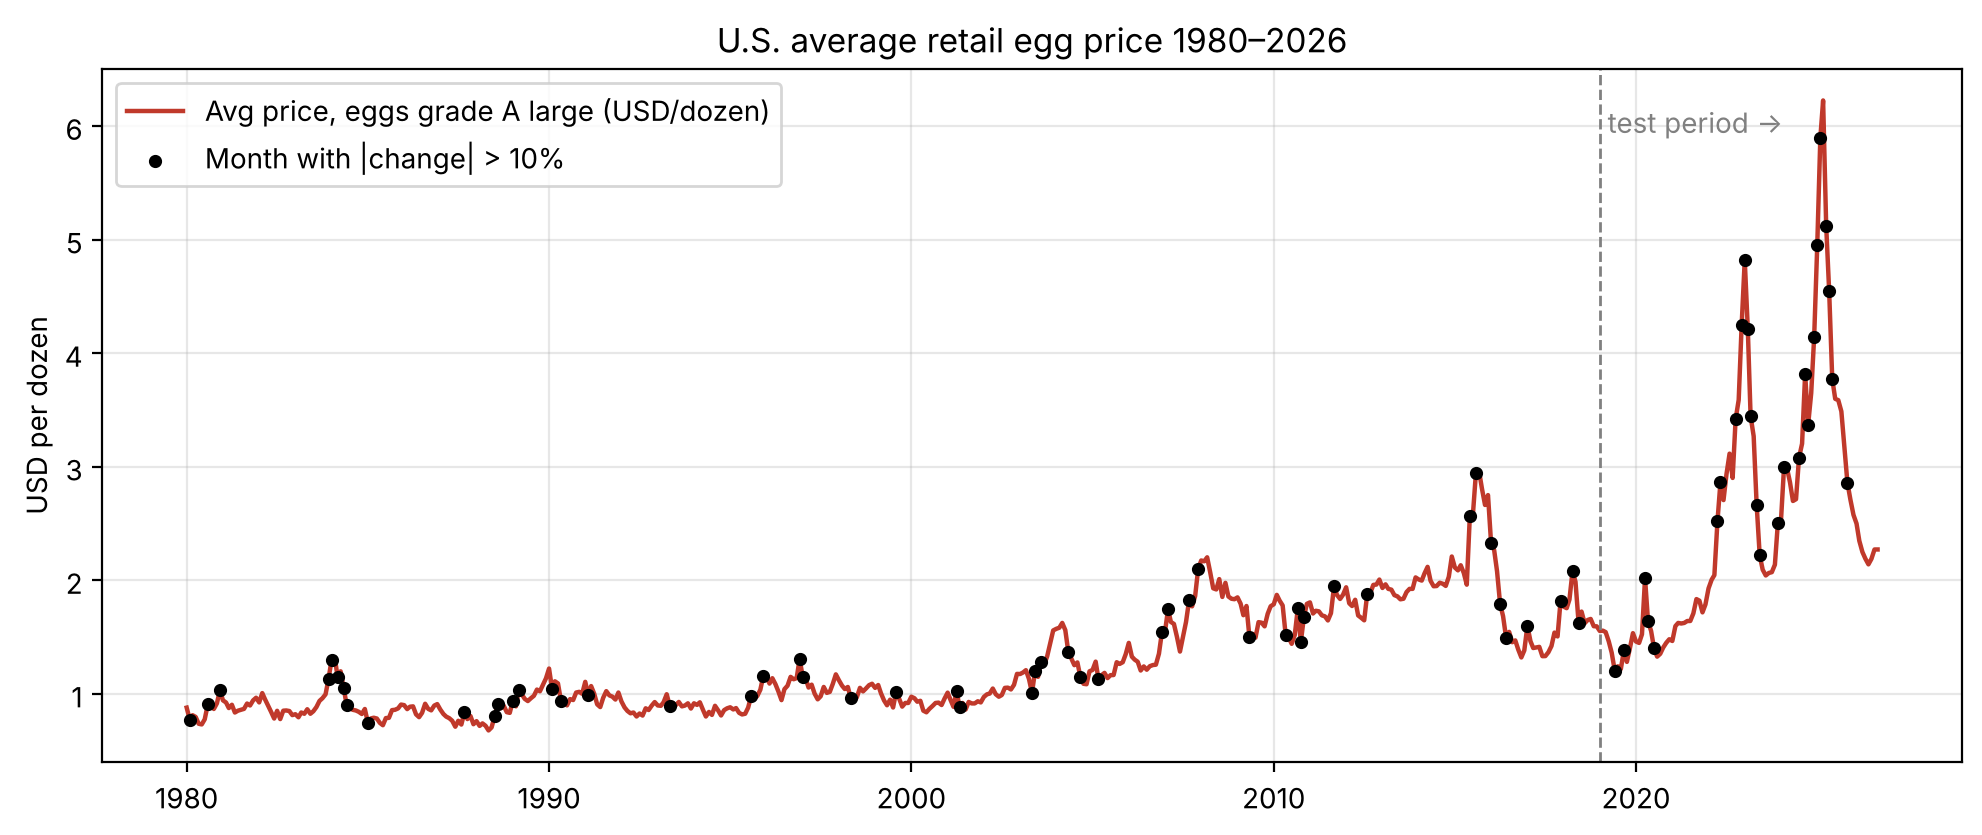

ราคาเฉลี่ยรายทศวรรษ: {1980: 0.88, 1990: 0.97, 2000: 1.33, 2010: 1.8, 2020: 2.65}
→ ราคาเฉลี่ยทศวรรษล่าสุดสูงกว่าทศวรรษ 1980 ถึง 3.0 เท่า: ข้อมูลมีเทรนด์ (non-stationary)
  โมเดลต้นไม้ทายเกินค่าที่เคยเห็นไม่ได้ จึงเปลี่ยน target เป็น "% การเปลี่ยนแปลงเดือนหน้า"


In [ ]:
# 4.1 ราคาตลอดช่วง + เดือนที่ราคาเปลี่ยนแรงเกิน SPIKE
ret = np.log(price).diff()     # log-return รายเดือน ≈ % การเปลี่ยนแปลง
big = ret.abs() > SPIKE
fig, ax = plt.subplots()
ax.plot(price.index, price, color='#c0392b', lw=1.6, label='Avg price, eggs grade A large (USD/dozen)')
ax.scatter(price.index[big], price[big], s=14, color='black', zorder=3, label=f'Month with |change| > {SPIKE:.0%}')
ax.axvline(pd.Timestamp(TEST_START), color='grey', ls='--', lw=1)
ax.text(pd.Timestamp(TEST_START), ax.get_ylim()[1] * 0.95, ' test period →', color='grey', va='top')
ax.set_title('U.S. average retail egg price 1980–2026'); ax.set_ylabel('USD per dozen'); ax.legend(loc='upper left')
plt.show()

decade_mean = price.groupby((price.index.year // 10) * 10).mean()
print('ราคาเฉลี่ยรายทศวรรษ:', {int(k): round(float(v), 2) for k, v in decade_mean.items()})
print(f'→ ราคาเฉลี่ยทศวรรษล่าสุดสูงกว่าทศวรรษ 1980 ถึง {decade_mean.iloc[-1]/decade_mean.iloc[0]:.1f} เท่า: ข้อมูลมีเทรนด์ (non-stationary)')
print('  โมเดลต้นไม้ทายเกินค่าที่เคยเห็นไม่ได้ จึงเปลี่ยน target เป็น "% การเปลี่ยนแปลงเดือนหน้า"')

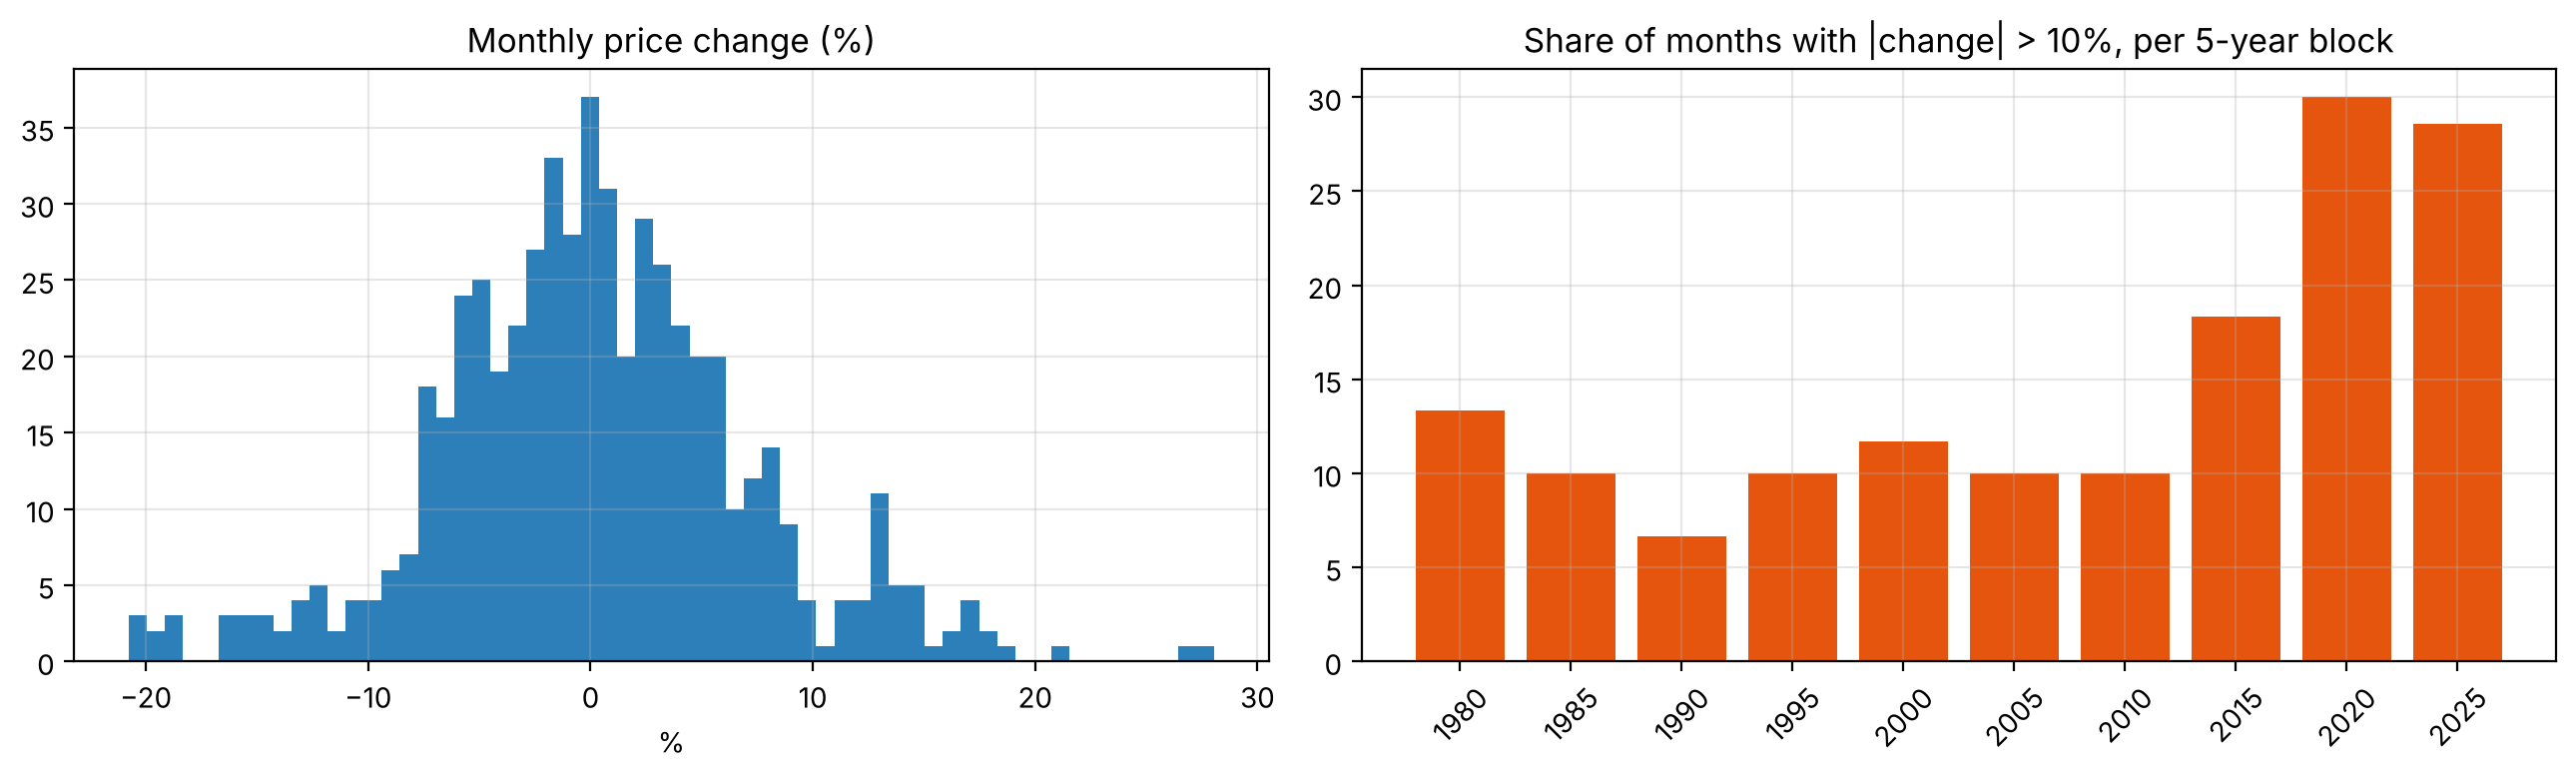

ค่า std ของการเปลี่ยนแปลงรายเดือน = 7.1%  | เดือนที่เปลี่ยนเกิน 10%: 78 จาก 560 เดือน
สัดส่วนเดือนที่เปลี่ยนแรง ต่อช่วง 5 ปี: {1980: '13%', 1985: '10%', 1990: '7%', 1995: '10%', 2000: '12%', 2005: '10%', 2010: '10%', 2015: '18%', 2020: '30%', 2025: '29%'}
→ ความผันผวนไม่เท่ากันทุกช่วง ช่วงหลัง 2015 แรงขึ้นชัดเจน ต้องแยกประเมินช่วงปกติ/ช่วงผันผวน (ขั้น 8)


In [ ]:
# 4.2 การเปลี่ยนแปลงรายเดือน: รุนแรงแค่ไหน และกระจุกตัวช่วงไหน
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(ret.dropna() * 100, bins=60, color='#2c7fb8')
axes[0].set_title('Monthly price change (%)'); axes[0].set_xlabel('%')
share = big.groupby(ret.index.year // 5 * 5).mean() * 100
axes[1].bar(share.index.astype(str), share.values, color='#e6550d')
axes[1].set_title(f'Share of months with |change| > {SPIKE:.0%}, per 5-year block'); axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

print(f'ค่า std ของการเปลี่ยนแปลงรายเดือน = {ret.std()*100:.1f}%  | เดือนที่เปลี่ยนเกิน {SPIKE:.0%}: {big.sum()} จาก {ret.notna().sum()} เดือน')
print('สัดส่วนเดือนที่เปลี่ยนแรง ต่อช่วง 5 ปี:', {int(k): f'{v:.0f}%' for k, v in share.items()})
print('→ ความผันผวนไม่เท่ากันทุกช่วง ช่วงหลัง 2015 แรงขึ้นชัดเจน ต้องแยกประเมินช่วงปกติ/ช่วงผันผวน (ขั้น 8)')

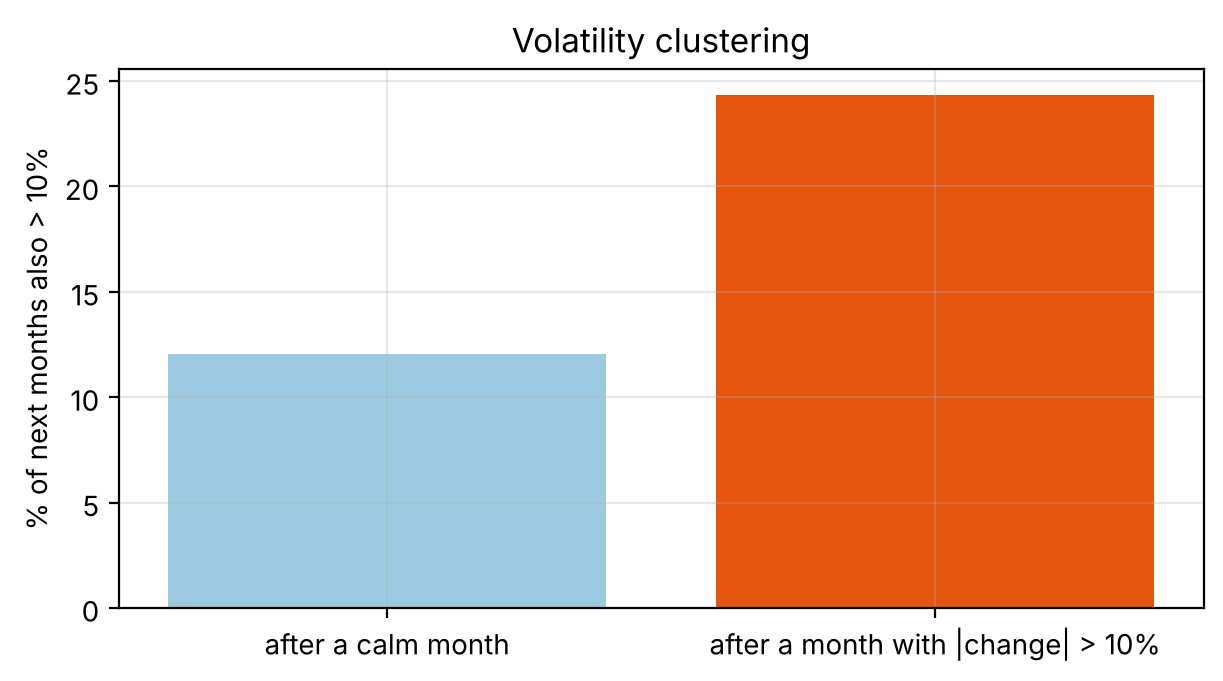

เดือนถัดจากเดือนที่เปลี่ยนแรง มีโอกาสเปลี่ยนแรงต่อ 24% vs หลังเดือนปกติ 12%
→ ความผันผวนเกาะกลุ่ม จึงใส่ feature vol_3 (ความผันผวน 3 เดือนล่าสุด) และใช้ vol_6 แบ่งช่วงปกติ/ผันผวนตอนวิเคราะห์ (ขั้น 8)


In [ ]:
# 4.3 ความผันผวนเกิดเป็นกลุ่มไหม: ถ้าเดือนนี้เปลี่ยนแรง เดือนหน้ามีโอกาสเปลี่ยนแรงต่อแค่ไหน
nxt_big = big.shift(-1)
valid = ret.notna() & nxt_big.notna() & ret.shift(-1).notna()
p_after_big   = nxt_big[valid & big].astype(float).mean()
p_after_quiet = nxt_big[valid & ~big].astype(float).mean()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(['after a calm month', f'after a month with |change| > {SPIKE:.0%}'], [p_after_quiet * 100, p_after_big * 100], color=['#9ecae1', '#e6550d'])
ax.set_ylabel('% of next months also > 10%'); ax.set_title('Volatility clustering')
plt.show()
print(f'เดือนถัดจากเดือนที่เปลี่ยนแรง มีโอกาสเปลี่ยนแรงต่อ {p_after_big:.0%} vs หลังเดือนปกติ {p_after_quiet:.0%}')
print('→ ความผันผวนเกาะกลุ่ม จึงใส่ feature vol_3 (ความผันผวน 3 เดือนล่าสุด) และใช้ vol_6 แบ่งช่วงปกติ/ผันผวนตอนวิเคราะห์ (ขั้น 8)')

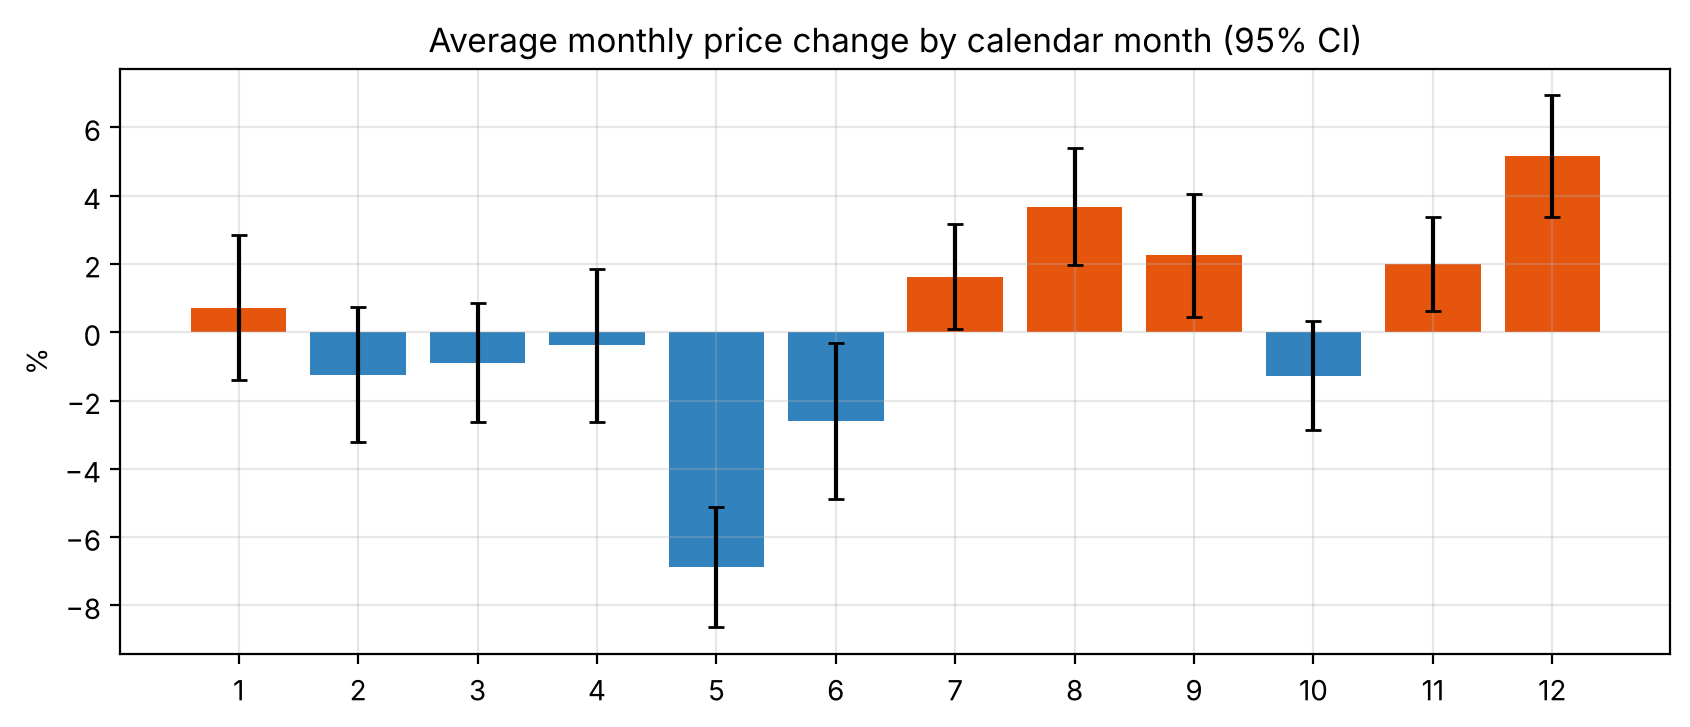

เดือนที่ค่าเฉลี่ยต่างจาก 0 อย่างมีนัยสำคัญ: {5: '-6.9%', 6: '-2.6%', 7: '+1.6%', 8: '+3.7%', 9: '+2.2%', 11: '+2.0%', 12: '+5.2%'}
→ มีรูปแบบฤดูกาลบางส่วน จึงใส่ feature month_sin / month_cos


In [ ]:
# 4.4 ฤดูกาล: แต่ละเดือนของปี ราคามักขึ้นหรือลง
season = ret.groupby(ret.index.month).agg(['mean', 'std', 'count'])
se = season['std'] / np.sqrt(season['count'])
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(season.index, season['mean'] * 100, yerr=1.96 * se * 100, capsize=3,
       color=np.where(season['mean'] > 0, '#e6550d', '#3182bd'))
ax.set_xticks(range(1, 13)); ax.set_title('Average monthly price change by calendar month (95% CI)'); ax.set_ylabel('%')
plt.show()
sig = season[(season['mean'].abs() > 1.96 * se)]
print('เดือนที่ค่าเฉลี่ยต่างจาก 0 อย่างมีนัยสำคัญ:', {m: f'{v*100:+.1f}%' for m, v in sig['mean'].items()})
print('→ มีรูปแบบฤดูกาลบางส่วน จึงใส่ feature month_sin / month_cos')

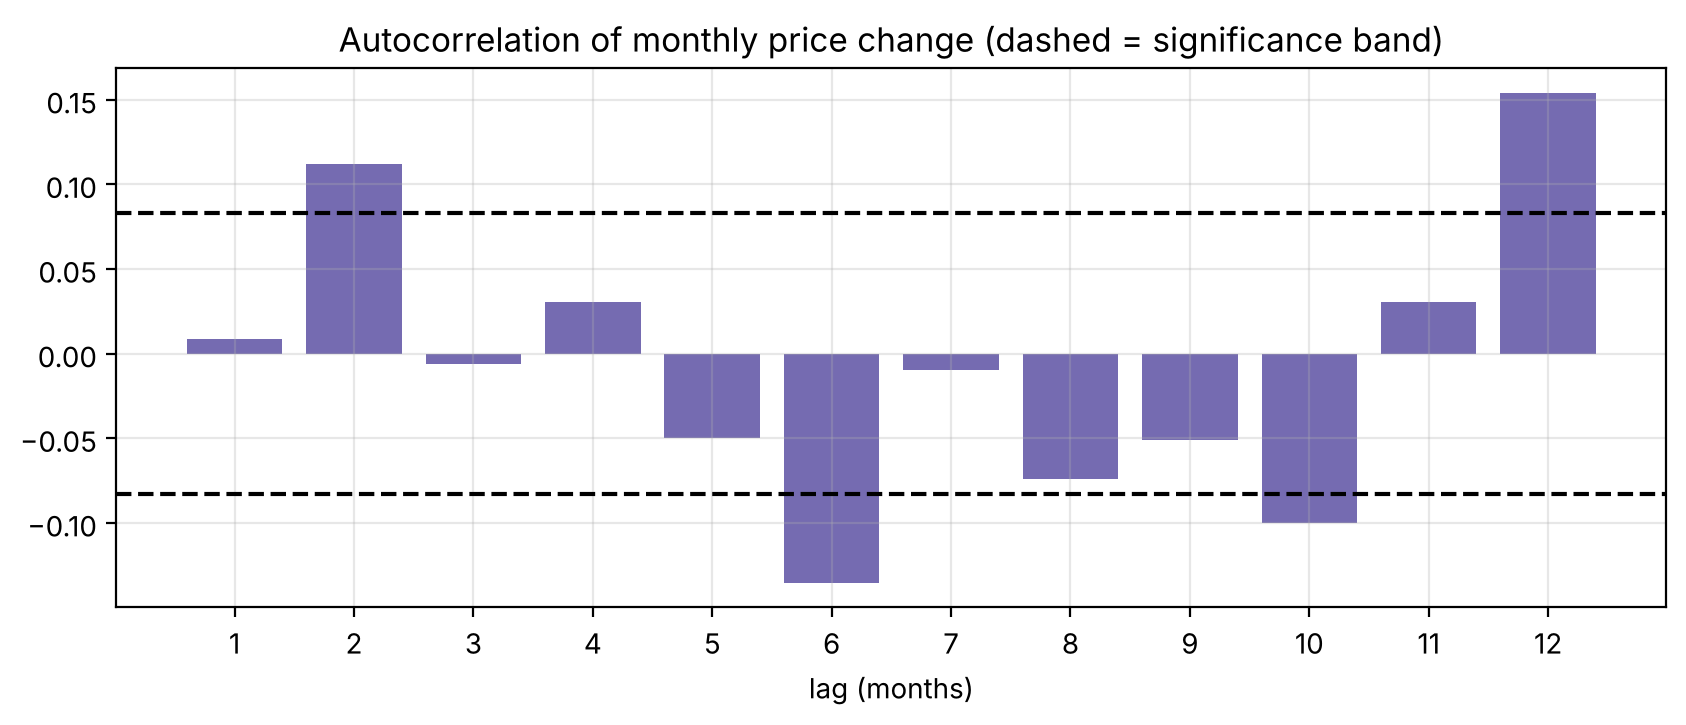

lag ที่มีนัยสำคัญ: {2: 0.11, 6: -0.14, 10: -0.1, 12: 0.15}
→ การเปลี่ยนแปลงไม่ได้สุ่มล้วน มีข้อมูลให้ใช้ทาย จึงใส่ ret_0, ret_1, ret_2 เป็น feature


In [ ]:
# 4.5 Autocorrelation: การเปลี่ยนแปลงเดือนนี้ บอกเดือนถัดๆ ไปได้ไหม
lags = range(1, 13)
acf = [ret.autocorr(lag=k) for k in lags]
band = 1.96 / np.sqrt(ret.notna().sum())
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(lags, acf, color='#756bb1'); ax.axhline(band, ls='--', c='k'); ax.axhline(-band, ls='--', c='k')
ax.set_xticks(list(lags)); ax.set_title('Autocorrelation of monthly price change (dashed = significance band)'); ax.set_xlabel('lag (months)')
plt.show()
sig_lags = [k for k, a in zip(lags, acf) if abs(a) > band]
print('lag ที่มีนัยสำคัญ:', {k: round(float(acf[k-1]), 2) for k in sig_lags})
print('→ การเปลี่ยนแปลงไม่ได้สุ่มล้วน มีข้อมูลให้ใช้ทาย จึงใส่ ret_0, ret_1, ret_2 เป็น feature')

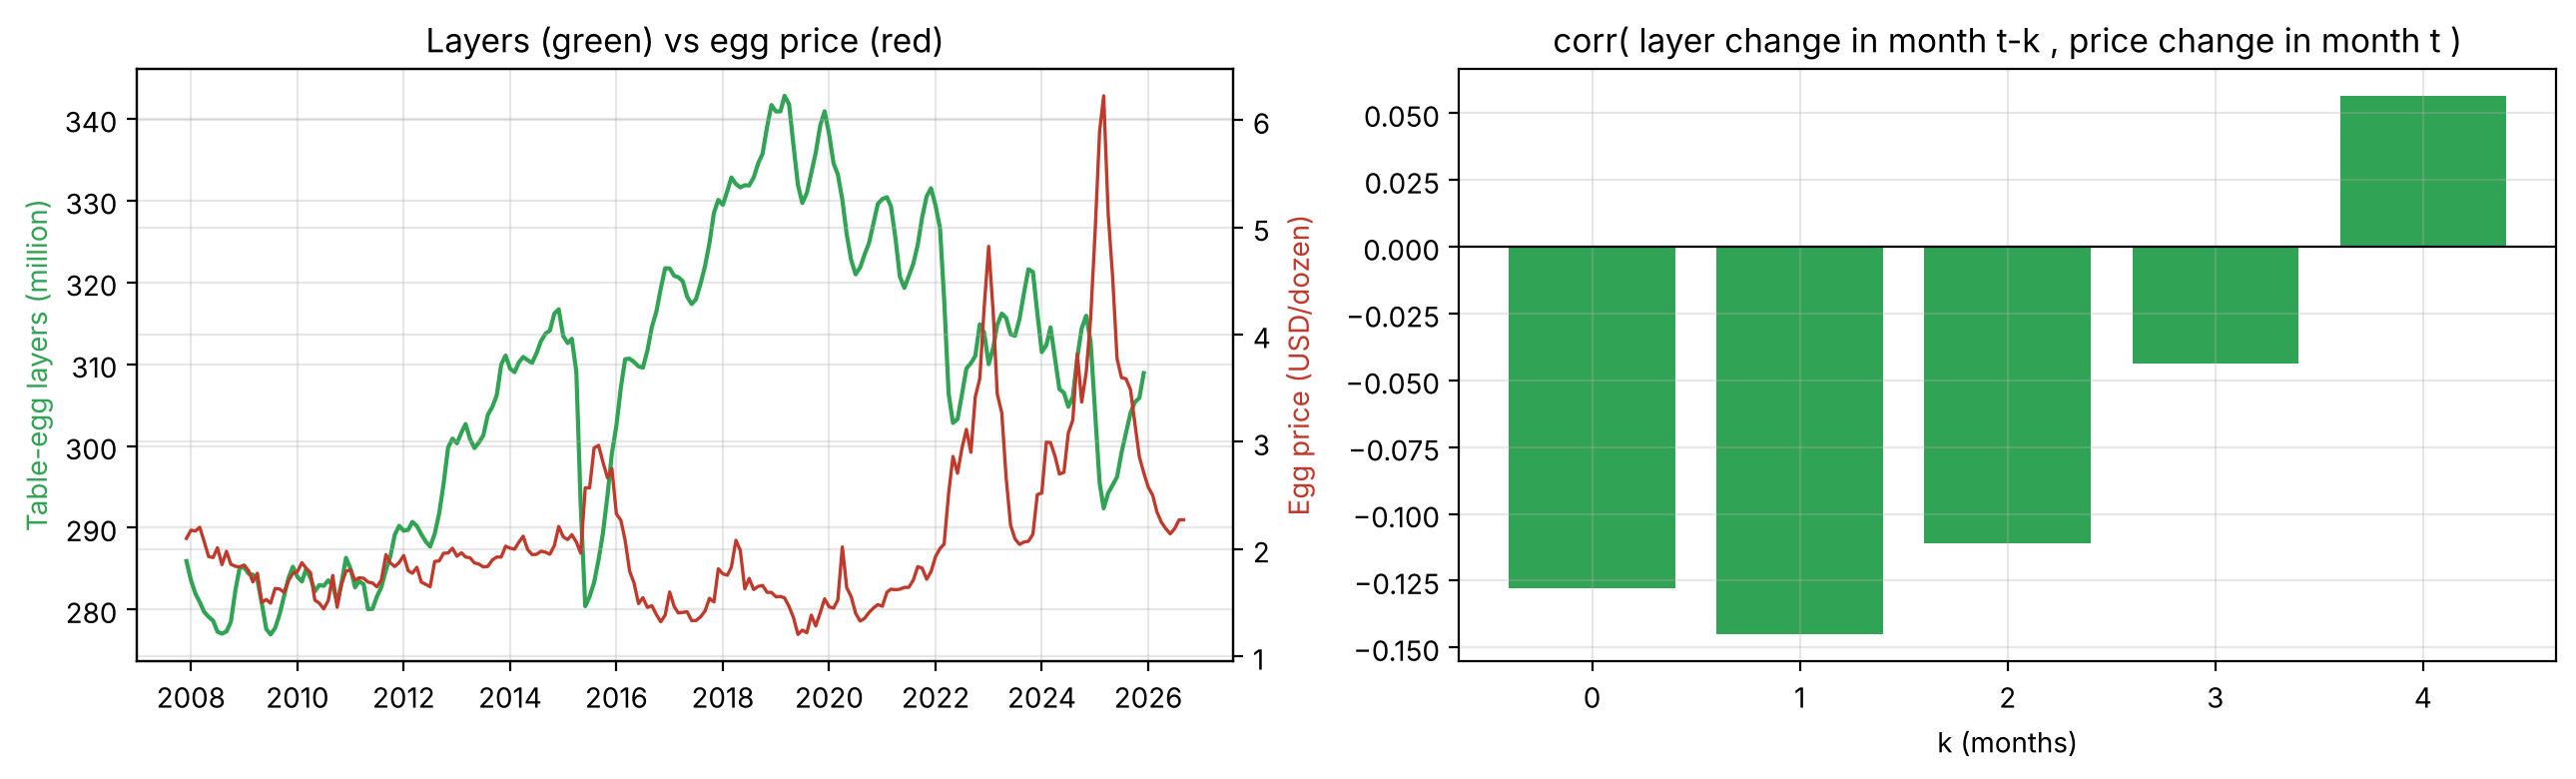

correlation ตาม lag: {0: -0.13, 1: -0.15, 2: -0.11, 3: -0.04, 4: 0.06}
แม่ไก่ลดลงสูงสุด: ระบาด 2015 = -11% | ช่วง 2022-2025 = -12%
→ ค่าเป็นลบ = แม่ไก่ลด ราคาขึ้น; ใช้ lag ≥ 1 เท่านั้นเพราะ NASS ประกาศช้า ถ้า lag 1-2 ยังมีค่าลบชัด แปลว่ามีประโยชน์ในการทาย


In [ ]:
# 4.6 จำนวนแม่ไก่ไข่ลดลง → ราคาไข่ขึ้นตามไหม และช้ากี่เดือน (ช่วงที่มีข้อมูล NASS)
lay_ret = np.log(layers).diff().reindex(ret.index)
xc = {k: ret.corr(lay_ret.shift(k)) for k in range(0, 5)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(layers.index, layers / 1e6, color='#31a354')
ax.set_ylabel('Table-egg layers (million)', color='#31a354')
ax2 = ax.twinx(); ax2.plot(price.loc[layers.index[0]:].index, price.loc[layers.index[0]:], color='#c0392b', lw=1.2)
ax2.set_ylabel('Egg price (USD/dozen)', color='#c0392b')
ax.set_title('Layers (green) vs egg price (red)')
axes[1].bar(list(xc.keys()), list(xc.values()), color='#31a354')
axes[1].axhline(0, c='k', lw=0.8)
axes[1].set_title('corr( layer change in month t-k , price change in month t )'); axes[1].set_xlabel('k (months)')
plt.tight_layout(); plt.show()

drop15 = layers['2015-01-01':'2015-12-01'].min() / layers['2014-10-01':'2015-03-01'].max() - 1
drop25 = layers['2022-01-01':'2025-12-01'].min() / layers['2021-10-01':'2022-01-01'].max() - 1
print('correlation ตาม lag:', {k: round(float(v), 2) for k, v in xc.items()})
print(f'แม่ไก่ลดลงสูงสุด: ระบาด 2015 = {drop15:.0%} | ช่วง 2022-2025 = {drop25:.0%}')
print(f'→ ค่าเป็นลบ = แม่ไก่ลด ราคาขึ้น; ใช้ lag ≥ {LAYERS_LAG} เท่านั้นเพราะ NASS ประกาศช้า ถ้า lag {LAYERS_LAG}-2 ยังมีค่าลบชัด แปลว่ามีประโยชน์ในการทาย')

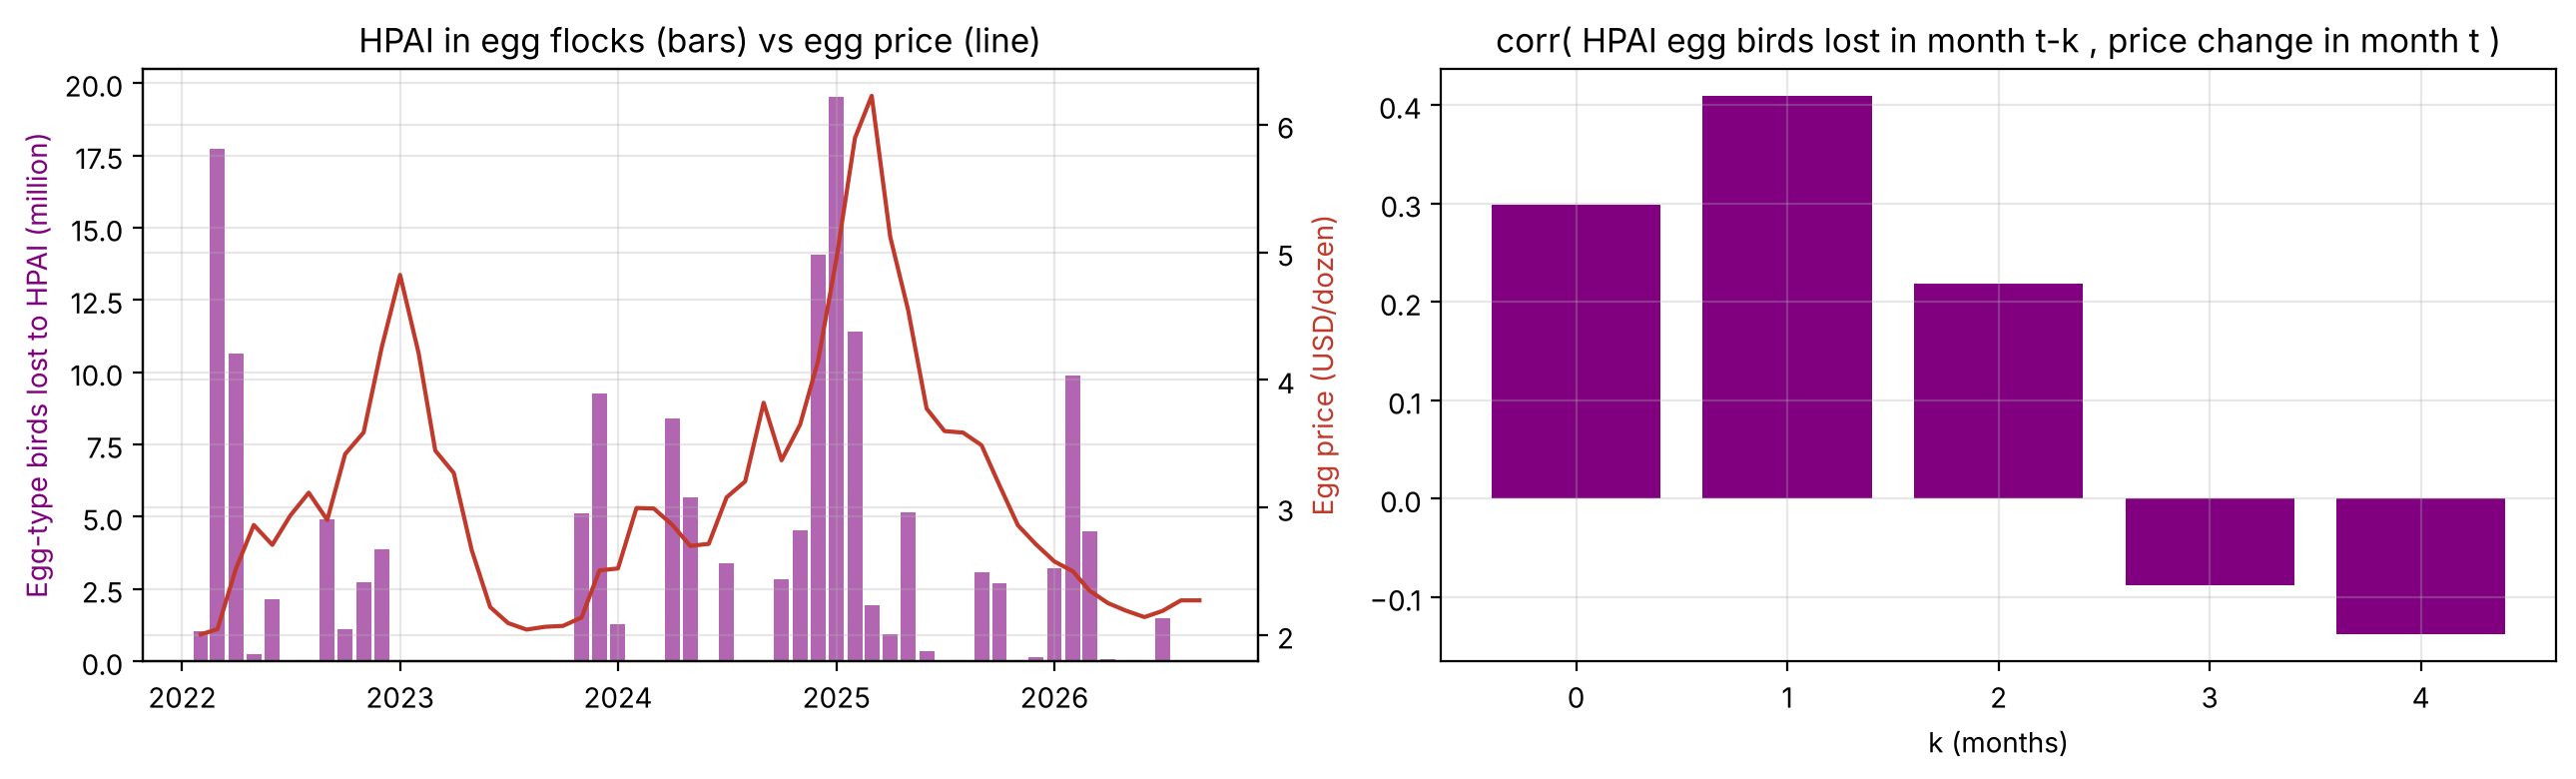

correlation ตาม lag: {0: 0.3, 1: 0.41, 2: 0.22, 3: -0.09, 4: -0.14}
→ แรงสุดที่ lag 1 | เทียบกับแม่ไก่ (4.6) ที่ |corr| ≈ 0.15


In [ ]:
# 4.7 ไก่ไข่ติดไข้หวัดนกเดือน t-k สัมพันธ์กับการเปลี่ยนแปลงราคาเดือน t แค่ไหน (ช่วงที่มีข้อมูลจริง 2022-02 →)
xh  = np.log1p(hpai)
win = ret.index >= '2022-02-01'
xc_h = {k: ret[win].corr(xh.shift(k)[win]) for k in range(0, 5)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.bar(hpai[win].index, hpai[win], width=25, color='purple', alpha=0.6)
ax.set_ylabel('Egg-type birds lost to HPAI (million)', color='purple')
ax2 = ax.twinx(); ax2.plot(price[win].index, price[win], color='#c0392b'); ax2.set_ylabel('Egg price (USD/dozen)', color='#c0392b')
ax.set_title('HPAI in egg flocks (bars) vs egg price (line)')
axes[1].bar(list(xc_h.keys()), list(xc_h.values()), color='purple')
axes[1].set_title('corr( HPAI egg birds lost in month t-k , price change in month t )'); axes[1].set_xlabel('k (months)')
plt.tight_layout(); plt.show()
best_k = max(xc_h, key=lambda k: xc_h[k])
print('correlation ตาม lag:', {k: round(float(v), 2) for k, v in xc_h.items()})
print(f'→ แรงสุดที่ lag {best_k} | เทียบกับแม่ไก่ (4.6) ที่ |corr| ≈ {max(abs(v) for v in xc.values()):.2f}')

## ขั้น 5 · สร้าง features
**target** = log-return เดือนหน้า `log(price[t+1] / price[t])` แล้วแปลงกลับเป็นราคา `price[t] × exp(ทายได้)`

| feature | ความหมาย | รู้ ณ เดือน t ไหม | มาจาก EDA ข้อ |
|---|---|---|---|
| ret_0, ret_1, ret_2 | % เปลี่ยนแปลงเดือน t, t-1, t-2 | ✓ | 4.5 |
| vol_3 | ความผันผวน 3 เดือนล่าสุด | ✓ | 4.2, 4.3 |
| dev_12 | ราคาตอนนี้แพงกว่าค่าเฉลี่ย 12 เดือนแค่ไหน (ช่วยจับการ "ย่อตัว" หลังพุ่ง) | ✓ | 4.1 |
| month_sin, month_cos | เดือนของปี | ✓ | 4.4 |

In [ ]:
# 5.1 ฟังก์ชันสร้าง feature (ทุกตัวใช้ข้อมูลถึงเดือน t เท่านั้น)
def make_features(price):
    r = np.log(price).diff()
    X = pd.DataFrame(index=price.index)
    X['ret_0'], X['ret_1'], X['ret_2'] = r, r.shift(1), r.shift(2)
    X['vol_3']     = r.rolling(3).std()
    X['vol_6']     = r.rolling(6).std()          # ใช้แบ่งช่วงปกติ/ผันผวนในขั้น 8 (ไม่ได้ใช้เป็น feature)
    X['dev_12']    = np.log(price / price.rolling(12).mean())
    X['month_sin'] = np.sin(2 * np.pi * price.index.month / 12)
    X['month_cos'] = np.cos(2 * np.pi * price.index.month / 12)
    X['target']    = r.shift(-1)          # สิ่งที่ต้องทาย: การเปลี่ยนแปลงเดือนหน้า
    X['price']     = price
    X['price_next']= price.shift(-1)
    return X

data = make_features(price)
FEATS = ['ret_0', 'ret_1', 'ret_2', 'vol_3', 'dev_12', 'month_sin', 'month_cos']
data[FEATS + ['target']].dropna().tail()

,ret_0,ret_1,ret_2,vol_3,dev_12,month_sin,month_cos,target
date,,,,,,,,
2026-04-01,-0.042634,-0.062727,-0.030335,0.016351,-0.326315,8.660254e-01,-0.500000,-0.026572
2026-05-01,-0.026572,-0.042634,-0.062727,0.018115,-0.287825,5.000000e-01,-0.866025,-0.023085
2026-06-01,-0.023085,-0.026572,-0.042634,0.010427,-0.263184,1.224647e-16,-1.000000,0.022172
2026-07-01,0.022172,-0.023085,-0.026572,0.027192,-0.197916,-5.000000e-01,-0.866025,0.037216
2026-08-01,0.037216,0.022172,-0.023085,0.031387,-0.118761,-8.660254e-01,-0.500000,0.000000


In [ ]:
# 5.2 ตรวจ leakage แบบอัตโนมัติ: feature ทุกตัวต้องไม่สัมพันธ์กับอนาคตมากกว่าปัจจุบันแบบผิดปกติ
# วิธีง่าย: target ของแถว t ต้องเท่ากับ ret_0 ของแถว t+1 พอดี (ยืนยันว่า target คืออนาคต 1 เดือน)
check = (data['target'].shift(1) - data['ret_0']).abs().max()
print('ความต่างสูงสุดระหว่าง target[t-1] กับ ret_0[t] =', check, '→ ตรง (target คือเดือนถัดไปจริง)' if check < 1e-12 else '→ ผิด!')

ความต่างสูงสุดระหว่าง target[t-1] กับ ret_0[t] = 0.0 → ตรง (target คือเดือนถัดไปจริง)


## ขั้น 6 · ตั้งวิธีประเมิน
**Walk-forward validation:** ทุกเดือนในช่วงทดสอบ เทรนโมเดลใหม่ด้วยข้อมูล *ก่อนหน้า* เดือนนั้นเท่านั้น แล้วทาย 1 เดือนข้างหน้า เหมือนใช้งานจริงทุกเดือน (ดีกว่าแบ่ง test ก้อนเดียวเพราะโมเดลได้เห็นข้อมูลใหม่เหมือนชีวิตจริง และไม่มีทางแอบเห็นอนาคต)

**Baseline (Naive):** ราคาเดือนหน้า = ราคาเดือนนี้

In [ ]:
# 6.1 walk-forward: ทุกเดือน t เทรนด้วยแถวที่ index < t (target ของแถวเหล่านั้นรู้แล้ว ณ สิ้นเดือน t)
def walk_forward(data, feats, make_model, test_idx):
    preds = {}
    for t in test_idx:
        train = data[data.index < t].dropna(subset=feats + ['target'])
        model = make_model().fit(train[feats], train['target'])
        preds[t] = model.predict(data.loc[[t], feats])[0]
    return pd.Series(preds)

MODELS = {
    'Ridge': lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'GBM'  : lambda: GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                                               subsample=0.8, random_state=SEED),
}

In [ ]:
# 6.2 ตัววัดผล
def evaluate(pred_ret, d):
    actual = d['price_next']
    pred   = d['price'] * np.exp(pred_ret)
    naive_mae = (actual - d['price']).abs().mean()
    mae  = (actual - pred).abs().mean()
    spikes = d['target'] > SPIKE
    return {
        'MAE ($/doz)' : round(mae, 3),
        'RMSE ($/doz)': round(np.sqrt(((actual - pred) ** 2).mean()), 3),
        'MASE'        : round(mae / naive_mae, 3),
        'Spike recall': f'{(pred_ret[spikes] > WARN).sum()}/{spikes.sum()}',
        'False alarms': int(((pred_ret > WARN) & ~spikes).sum()),
    }

## ขั้น 7 · สร้างโมเดลเทียบ baseline (R4)
ทุกโมเดลใช้ **ราคาย้อนหลังอย่างเดียว** ทดสอบแบบ walk-forward ตั้งแต่ `TEST_START` → เดือนล่าสุด (มีทั้งเดือนปกติและช่วงราคาพุ่ง 2022-2025)

- **Naive (baseline):** ราคาเดือนหน้า = ราคาเดือนนี้
- **Ridge:** linear regression ที่มี regularization ทาย % การเปลี่ยนแปลง
- **GBM:** Gradient Boosting ต้นไม้ตื้น ทาย % การเปลี่ยนแปลง

In [ ]:
# 7.1 รัน walk-forward ทุกโมเดล
test_idx = data.index[(data.index >= TEST_START) & data['target'].notna()]
dT = data.loc[test_idx]
preds = {'Naive': pd.Series(0.0, index=test_idx)}
for name, mk in MODELS.items():
    preds[name] = walk_forward(data, FEATS, mk, test_idx)

res = pd.DataFrame({k: evaluate(v, dT) for k, v in preds.items()}).T
best = res['MASE'].astype(float).drop('Naive').idxmin()
print(f'ทดสอบ {len(test_idx)} เดือน ({test_idx[0]:%Y-%m} → {test_idx[-1]:%Y-%m}) | โมเดลดีสุด: {best}')
res

ทดสอบ 92 เดือน (2019-01 → 2026-08) | โมเดลดีสุด: GBM


,MAE ($/doz),RMSE ($/doz),MASE,Spike recall,False alarms
Naive,0.212,0.319,1.0,0/14,0
Ridge,0.212,0.32,1.002,0/14,0
GBM,0.207,0.33,0.976,0/14,1


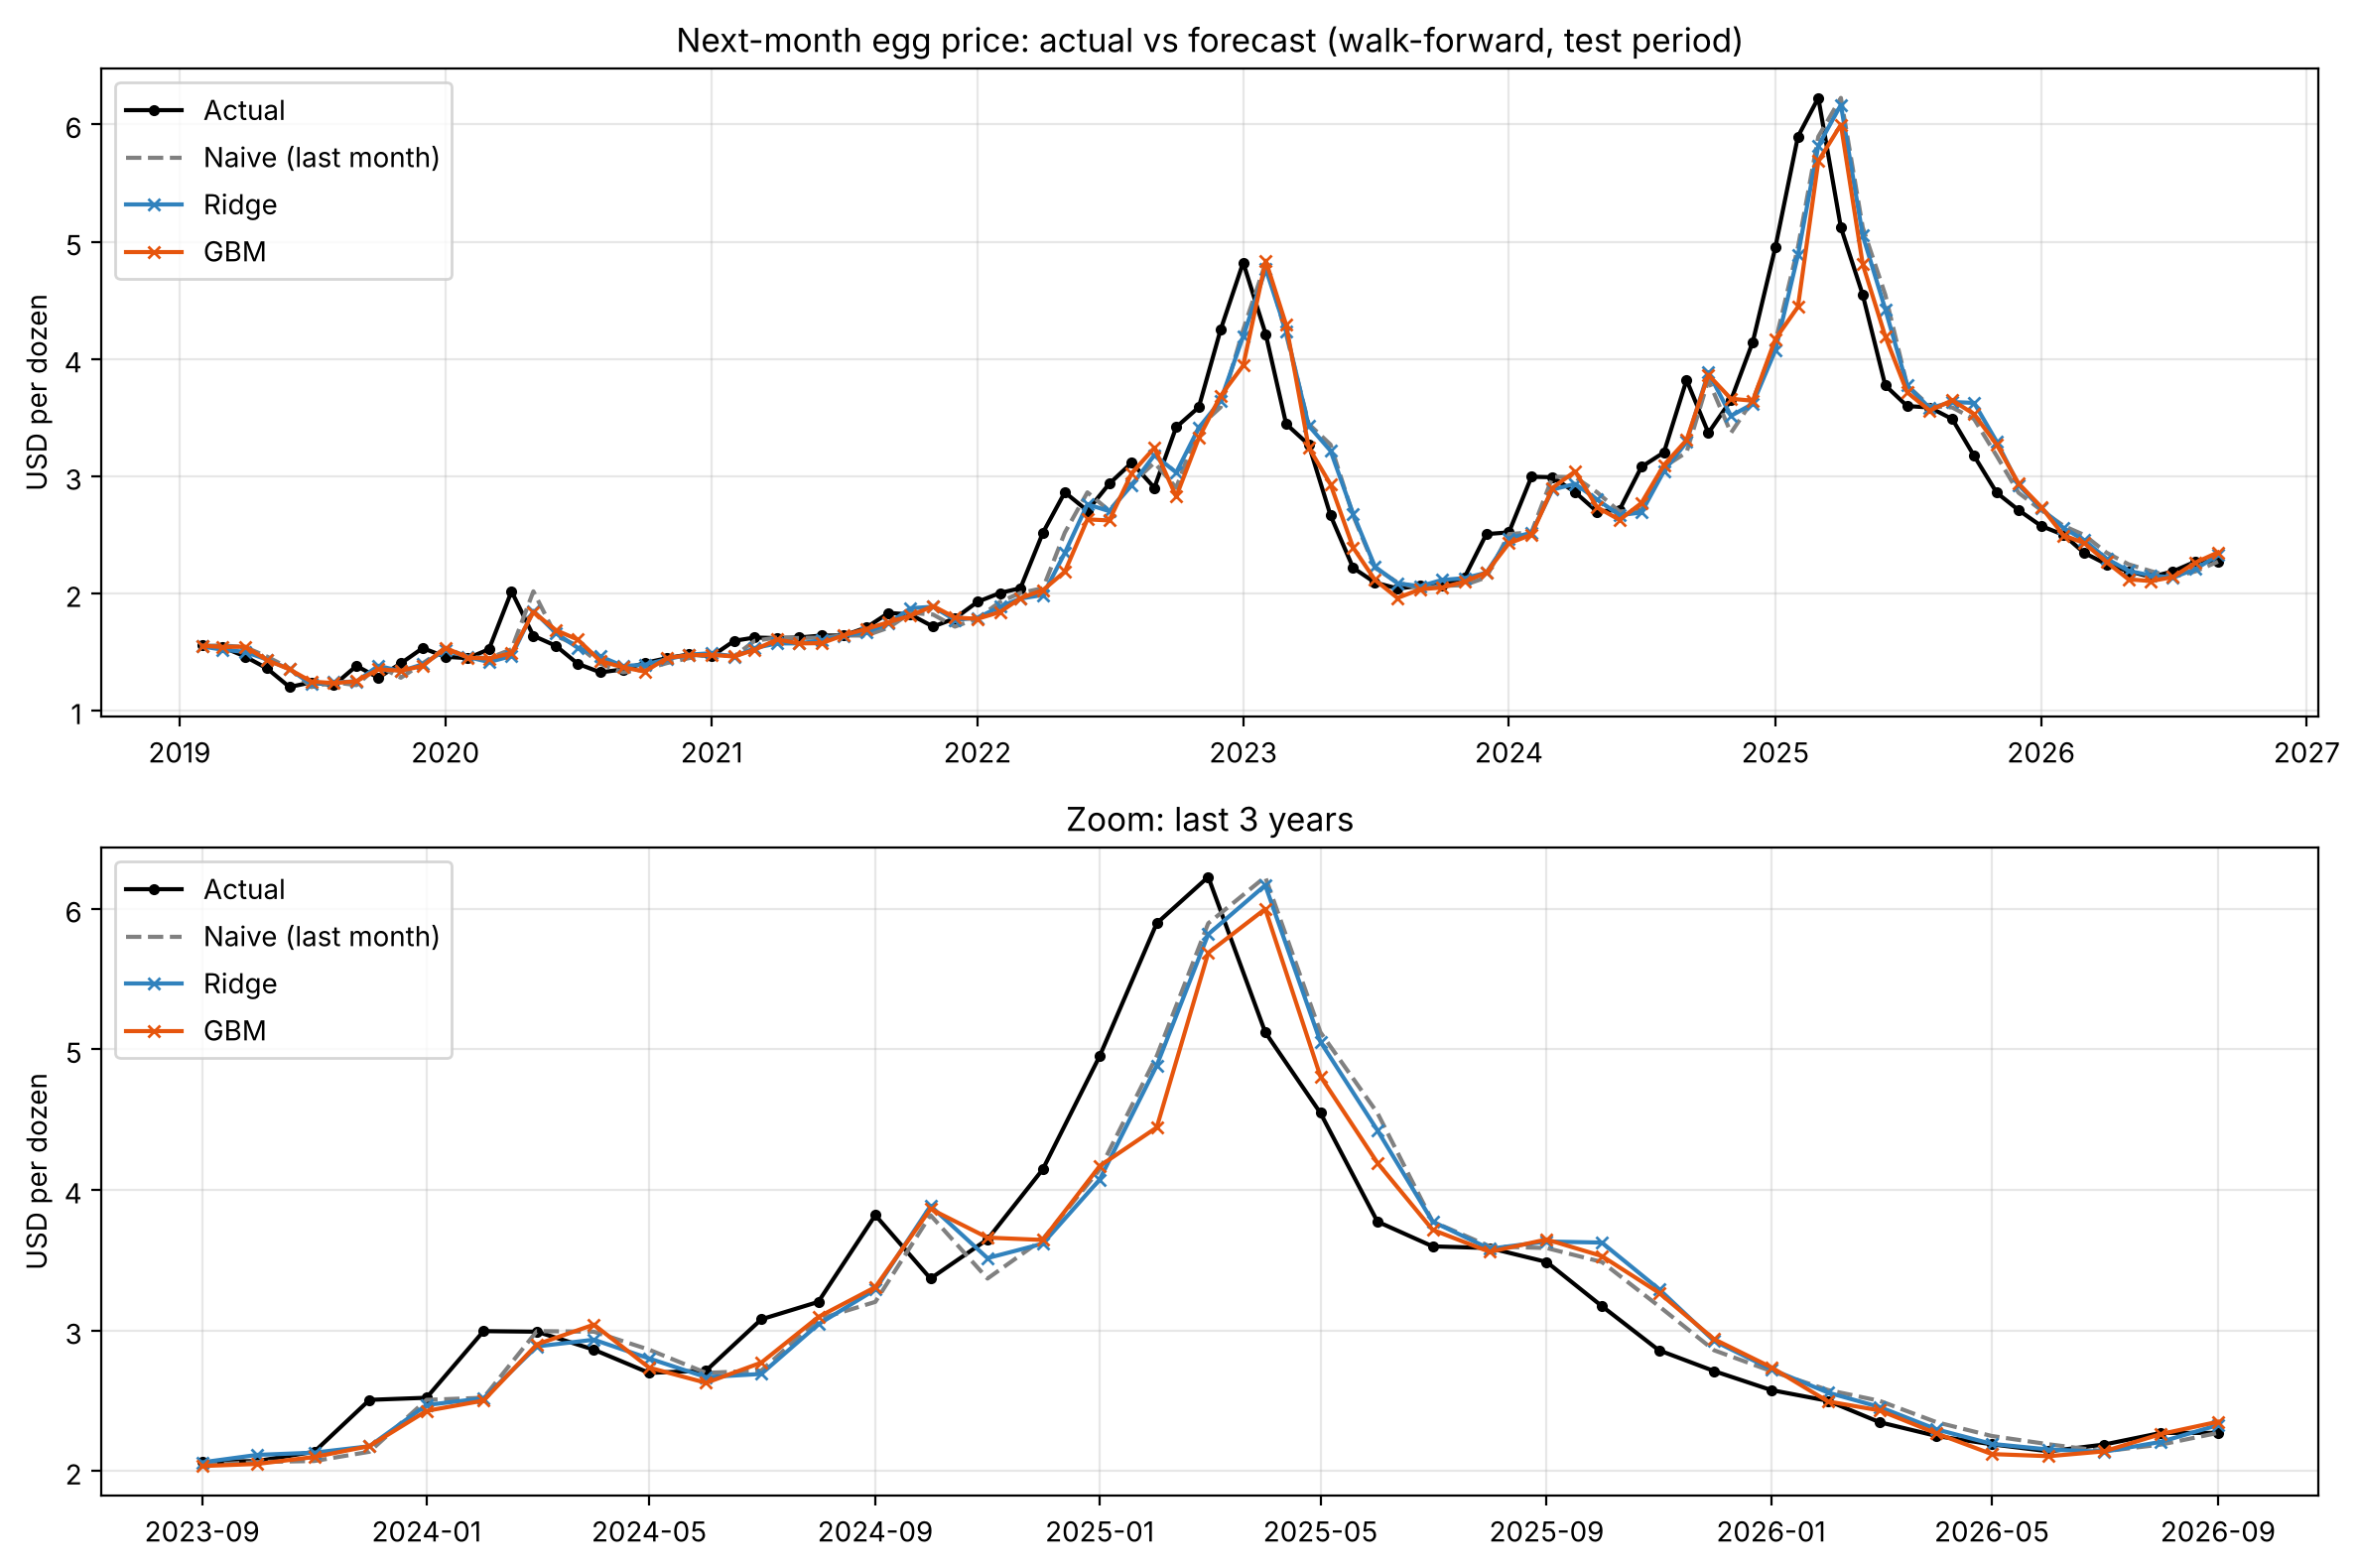

In [ ]:
# 7.2 กราฟเทียบราคาจริงกับที่ทาย (ทั้งช่วงทดสอบ และซูม 3 ปีล่าสุด)
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for ax, start in zip(axes, [test_idx[0], test_idx[-1] - pd.DateOffset(months=36)]):
    d = dT[dT.index >= start]
    x = d.index + pd.offsets.MonthBegin(1)        # แสดงที่เดือน t+1 (เดือนที่ถูกทาย)
    ax.plot(x, d['price_next'], 'k-o', ms=3, label='Actual')
    ax.plot(x, d['price'], '--', c='grey', label='Naive (last month)')
    for name, c in [('Ridge', '#3182bd'), ('GBM', '#e6550d')]:
        ax.plot(x, d['price'] * np.exp(preds[name].loc[d.index]), '-x', c=c, ms=4, label=name)
    ax.set_ylabel('USD per dozen'); ax.legend(loc='upper left')
axes[0].set_title('Next-month egg price: actual vs forecast (walk-forward, test period)')
axes[1].set_title('Zoom: last 3 years')
plt.tight_layout(); plt.show()

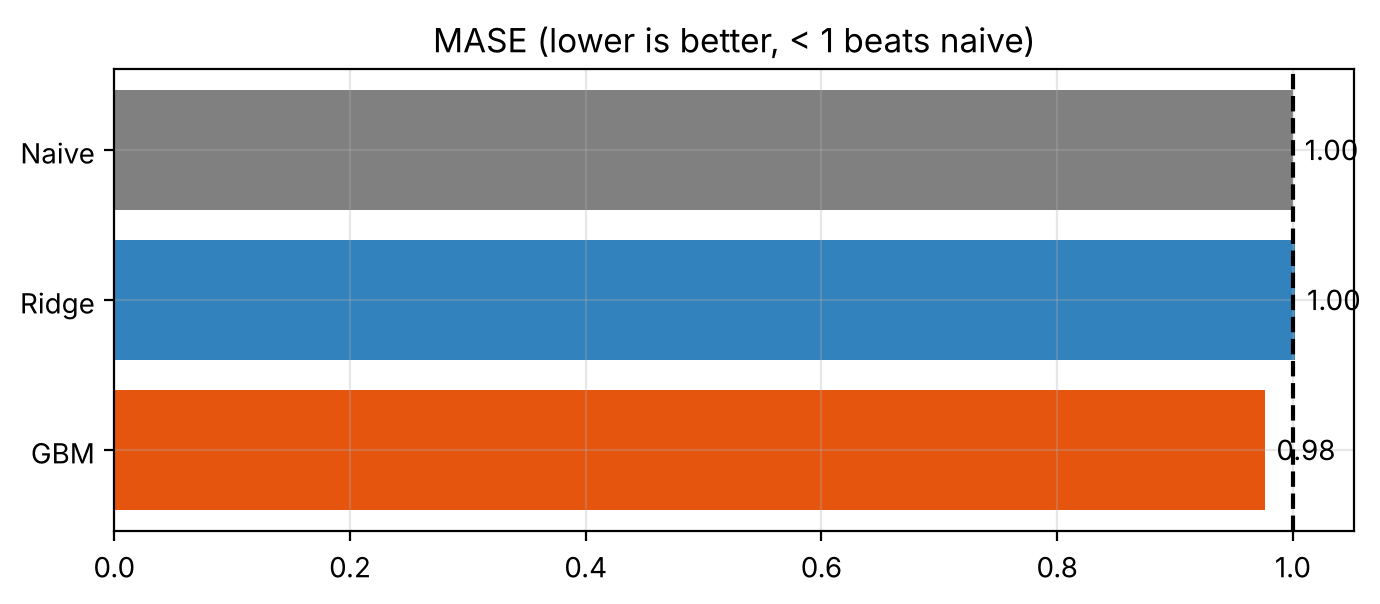

In [ ]:
# 7.3 กราฟแท่ง MASE สำหรับโปสเตอร์ (ต่ำกว่า 1 = ชนะ baseline)
fig, ax = plt.subplots(figsize=(8, 3))
m = res['MASE'].astype(float)
ax.barh(m.index, m.values, color=['grey' if i == 'Naive' else ('#e6550d' if i == best else '#3182bd') for i in m.index])
ax.axvline(1, c='k', ls='--'); ax.invert_yaxis()
for i, v in enumerate(m.values): ax.text(v + 0.01, i, f'{v:.2f}', va='center')
ax.set_title('MASE (lower is better, < 1 beats naive)')
plt.show()

### การทดลอง B: เพิ่มข้อมูลประกอบ แล้วเลือกเฉพาะกลุ่มตัวแปรที่ช่วยจริง
**กลุ่มตัวแปร**

| กลุ่ม | feature | รู้ ณ เดือน t ได้ไหม |
|---|---|---|
| ราคา (price) | ret_0, ret_1, ret_2, vol_3, dev_12, month_sin, month_cos | ✓ |
| แม่ไก่ไข่ (layers, NASS) | lay_chg_1, lay_chg_3, lay_dev_12 | ✓ ใช้ถึงเดือน t-1 เพราะ NASS ประกาศช้า |
| ไข้หวัดนก (HPAI, APHIS) | hpai_0, hpai_1, hpai_3m (log ล้านตัว) | ✓ APHIS ประกาศภายในไม่กี่วัน |

**วิธีเลือกตัวแปรแบบไม่โกง:** แบ่งช่วงทดสอบเป็น 2 ส่วน
1. **ช่วงคัดเลือก** (`TEST_B_START` → `SELECT_END`): ลองทุกชุดตัวแปร แล้วเก็บกลุ่มที่ทำให้ MASE ดีขึ้นอย่างน้อย `MIN_GAIN`
2. **ช่วงประเมิน** (หลัง `SELECT_END`): วัดผลชุดที่เลือกไว้ *ล่วงหน้า* — ถ้าเลือกจากช่วงที่ใช้วัดผลด้วย ผลจะดูดีเกินจริง

In [ ]:
# 7.4 สร้าง feature ข้อมูลประกอบ
lay_log = np.log(layers).reindex(data.index).shift(LAYERS_LAG)     # ณ เดือน t รู้แค่ถึง t-LAYERS_LAG
data['lay_chg_1']  = lay_log.diff(1)
data['lay_chg_3']  = lay_log.diff(3)
data['lay_dev_12'] = lay_log - lay_log.rolling(12).mean()
data['hpai_0']     = np.log1p(hpai)
data['hpai_1']     = data['hpai_0'].shift(1)
data['hpai_3m']    = np.log1p(hpai.rolling(3).sum())

GROUPS = {'layers': ['lay_chg_1', 'lay_chg_3', 'lay_dev_12'], 'HPAI': ['hpai_0', 'hpai_1', 'hpai_3m']}
SETS = {'price only': FEATS,
        '+ layers': FEATS + GROUPS['layers'],
        '+ HPAI': FEATS + GROUPS['HPAI'],
        '+ layers + HPAI': FEATS + GROUPS['layers'] + GROUPS['HPAI']}
for k, f in SETS.items():
    rows = data.dropna(subset=f + ['target'])
    print(f'{k:16s}: {len(f):2d} features | เทรนได้ {len(rows)} เดือน ({rows.index[0]:%Y-%m} → {rows.index[-1]:%Y-%m})')

price only      :  7 features | เทรนได้ 549 เดือน (1980-12 → 2026-08)
+ layers        : 10 features | เทรนได้ 206 เดือน (2008-12 → 2026-01)
+ HPAI          : 10 features | เทรนได้ 120 เดือน (2016-09 → 2026-08)
+ layers + HPAI : 13 features | เทรนได้ 113 เดือน (2016-09 → 2026-01)


In [ ]:
# 7.5 รัน walk-forward ทุกชุดตัวแปร × ทุกโมเดล (ราคาอย่างเดียวใช้ผลเดิมจาก 7.1)
test_B = data.index[(data.index >= TEST_B_START) & data['target'].notna()]
predB = {'Naive': pd.Series(0.0, index=test_B)}
for set_name, feats in SETS.items():
    for m, mk in MODELS.items():
        key = f'{m} {set_name}'
        if set_name == 'price only':
            predB[key] = preds[m].reindex(test_B)
        else:
            idx = test_B[data.loc[test_B, feats].notna().all(axis=1)]
            predB[key] = walk_forward(data, feats, mk, idx).reindex(test_B)

def compare(idx):
    d = data.loc[idx]
    return pd.DataFrame({k: evaluate(v.loc[idx], d) for k, v in predB.items()}).T

allB      = pd.concat(predB, axis=1)
common    = test_B[allB.notna().all(axis=1)]              # เดือนที่ทุกชุดทายได้ (ข้อมูลแม่ไก่จบ 2025-12)
sel_idx   = common[common <= SELECT_END]
eval_idx  = common[common > SELECT_END]
print(f'ช่วงคัดเลือก {len(sel_idx)} เดือน ({sel_idx[0]:%Y-%m} → {sel_idx[-1]:%Y-%m}) | ช่วงประเมิน {len(eval_idx)} เดือน ({eval_idx[0]:%Y-%m} → {eval_idx[-1]:%Y-%m})')

ช่วงคัดเลือก 24 เดือน (2022-06 → 2024-05) | ช่วงประเมิน 20 เดือน (2024-06 → 2026-01)


In [ ]:
# 7.6 ช่วงคัดเลือก: กลุ่มตัวแปรไหนช่วย → เลือกชุดตัวแปรและโมเดล
res_sel = compare(sel_idx)
mase_sel = res_sel['MASE'].astype(float)
best_of = lambda s: mase_sel[[f'{m} {s}' for m in MODELS]].min()
base = best_of('price only')
gain = {g: round(float(base - best_of(f'+ {g}')), 3) for g in GROUPS}
keep = [g for g, v in gain.items() if v >= MIN_GAIN]
SEL_NAME = 'price only' if not keep else '+ ' + ' + '.join(keep)
SEL_FEATS = SETS[SEL_NAME]
SEL_MODEL = min(MODELS, key=lambda m: mase_sel[f'{m} {SEL_NAME}'])
SEL_KEY = f'{SEL_MODEL} {SEL_NAME}'
display(res_sel)
print('MASE ดีขึ้นจากราคาอย่างเดียว (ยิ่งบวกยิ่งดี):', gain)
print(f'→ เก็บกลุ่ม: {keep if keep else "ไม่มี"} | ชุดที่เลือก: {SEL_KEY}')

,MAE ($/doz),RMSE ($/doz),MASE,Spike recall,False alarms
Naive,0.275,0.364,1.0,0/5,0
Ridge price only,0.268,0.352,0.977,0/5,0
GBM price only,0.27,0.374,0.982,0/5,0
Ridge + layers,0.261,0.385,0.951,1/5,1
GBM + layers,0.303,0.425,1.102,1/5,3
Ridge + HPAI,0.265,0.358,0.965,4/5,4
GBM + HPAI,0.252,0.326,0.918,3/5,2
Ridge + layers + HPAI,0.246,0.333,0.895,4/5,5
GBM + layers + HPAI,0.257,0.323,0.938,4/5,4


MASE ดีขึ้นจากราคาอย่างเดียว (ยิ่งบวกยิ่งดี): {'layers': 0.026, 'HPAI': 0.059}
→ เก็บกลุ่ม: ['layers', 'HPAI'] | ชุดที่เลือก: Ridge + layers + HPAI


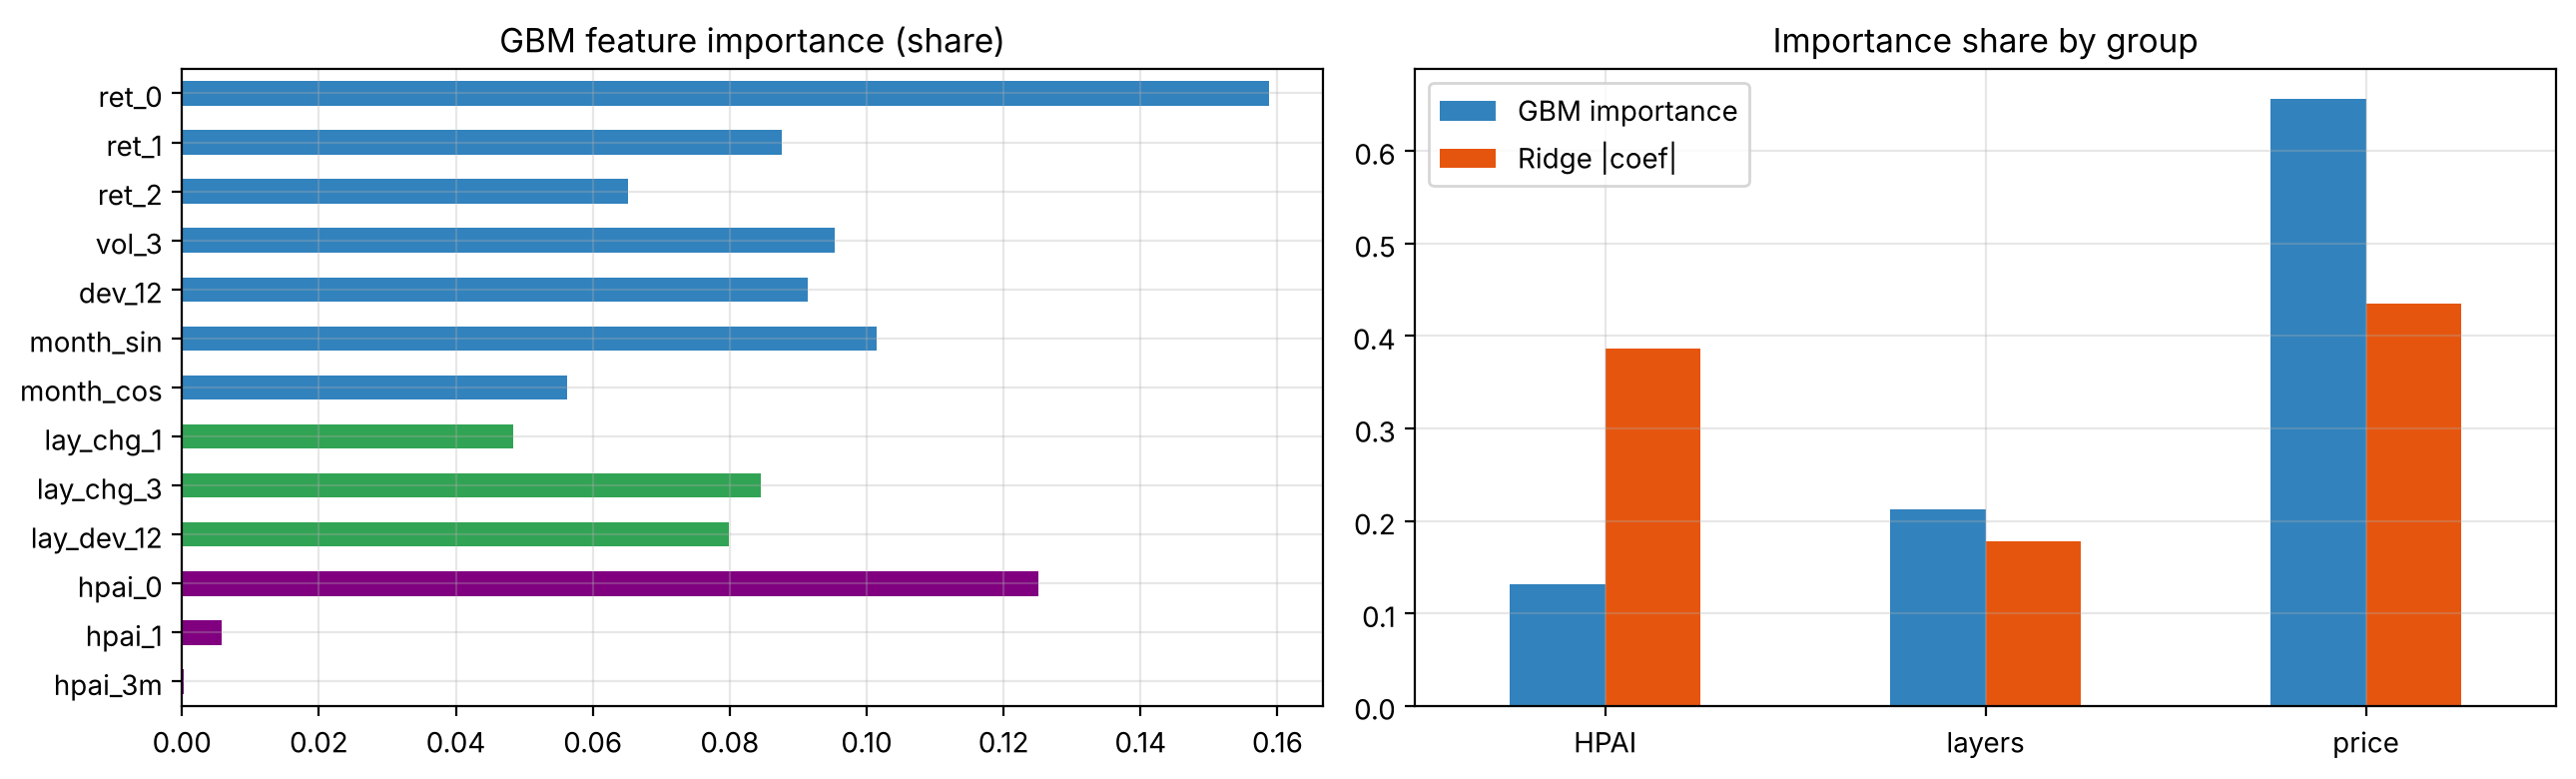

เทรนด้วย 93 เดือน (2016-09 → 2024-05)
สัดส่วนความสำคัญรายกลุ่ม:
        GBM importance  Ridge |coef|
HPAI              0.13          0.39
layers            0.21          0.18
price             0.66          0.44


In [ ]:
# 7.7 ตัวแปรไหนสำคัญ (อธิบายประกอบ): โมเดลเทรนด้วยข้อมูลถึง SELECT_END เท่านั้น ใช้ทุกตัวแปร
ALL = SETS['+ layers + HPAI']
tr = data[data.index <= SELECT_END].dropna(subset=ALL + ['target'])
gbm = MODELS['GBM']().fit(tr[ALL], tr['target'])
rdg = MODELS['Ridge']().fit(tr[ALL], tr['target'])
imp = pd.DataFrame({'GBM importance': gbm.feature_importances_, 'Ridge |coef|': np.abs(rdg[-1].coef_)}, index=ALL)
imp = imp / imp.sum()
grp = imp.groupby(lambda f: 'layers' if f.startswith('lay') else ('HPAI' if f.startswith('hpai') else 'price')).sum()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = ['purple' if f.startswith('hpai') else ('#31a354' if f.startswith('lay') else '#3182bd') for f in imp.index]
imp['GBM importance'].plot.barh(ax=axes[0], color=colors); axes[0].set_title('GBM feature importance (share)'); axes[0].invert_yaxis()
grp.plot.bar(ax=axes[1], rot=0, color=['#3182bd', '#e6550d']); axes[1].set_title('Importance share by group')
plt.tight_layout(); plt.show()
print(f'เทรนด้วย {len(tr)} เดือน ({tr.index[0]:%Y-%m} → {tr.index[-1]:%Y-%m})')
print('สัดส่วนความสำคัญรายกลุ่ม:'); print(grp.round(2).to_string())

In [ ]:
# 7.8 ช่วงประเมิน (ไม่ได้ใช้เลือก): ชุดที่เลือก vs ราคาอย่างเดียว vs Naive
res_eval = compare(eval_idx)
display(res_eval)
# ชุดที่เลือก ทายได้ยาวกว่า (ถ้าไม่ใช้แม่ไก่ ทายได้ถึงเดือนล่าสุด) → วัดอีกรอบบนทุกเดือนที่ทายได้
full_idx = test_B[(test_B > SELECT_END) & predB[SEL_KEY].notna()]
res_final = compare(full_idx).loc[['Naive', f'GBM price only', f'Ridge price only', SEL_KEY]].drop_duplicates()
print(f'ชุดที่เลือก {SEL_KEY} บนทุกเดือนในช่วงประเมินที่ทายได้: {len(full_idx)} เดือน ({full_idx[0]:%Y-%m} → {full_idx[-1]:%Y-%m})')
res_final

,MAE ($/doz),RMSE ($/doz),MASE,Spike recall,False alarms
Naive,0.407,0.507,1.0,0/5,0
Ridge price only,0.42,0.513,1.031,0/5,0
GBM price only,0.387,0.515,0.95,0/5,1
Ridge + layers,0.441,0.581,1.084,0/5,2
GBM + layers,0.432,0.613,1.062,0/5,2
Ridge + HPAI,0.396,0.539,0.974,3/5,5
GBM + HPAI,0.391,0.668,0.962,3/5,5
Ridge + layers + HPAI,0.448,0.623,1.102,3/5,5
GBM + layers + HPAI,0.427,0.71,1.05,3/5,4


ชุดที่เลือก Ridge + layers + HPAI บนทุกเดือนในช่วงประเมินที่ทายได้: 20 เดือน (2024-06 → 2026-01)


,MAE ($/doz),RMSE ($/doz),MASE,Spike recall,False alarms
Naive,0.407,0.507,1.0,0/5,0
GBM price only,0.387,0.515,0.95,0/5,1
Ridge price only,0.42,0.513,1.031,0/5,0
Ridge + layers + HPAI,0.448,0.623,1.102,3/5,5


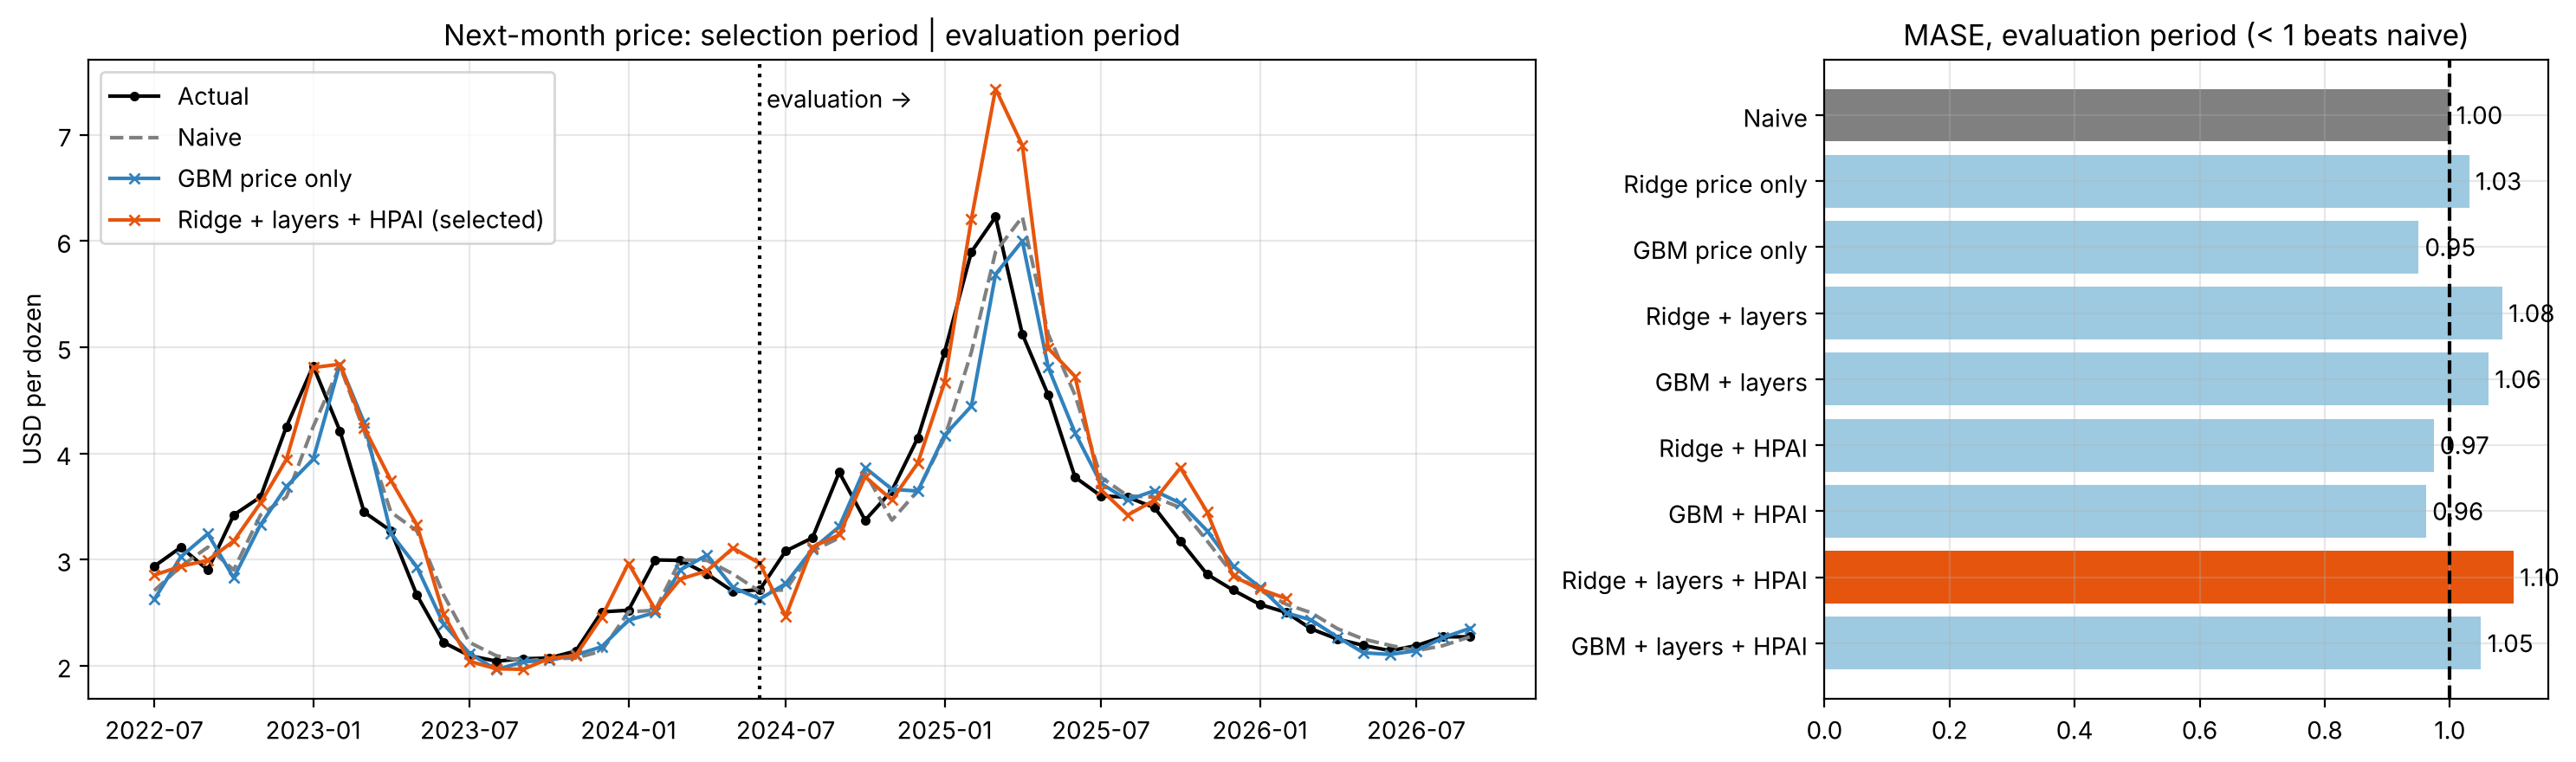

เดือนในช่วงประเมินที่ไก่ไข่ติดเชื้อ > 2 ล้านตัว:
            egg_birds_lost_M  actual_change_%  pred_change_% (selected)
date                                                                   
2024-07-01               3.4              3.9                       1.2
2024-10-01               2.8              8.0                       5.5
2024-11-01               4.5             12.8                       6.9
2024-12-01              14.1             17.8                      11.9
2025-01-01              19.5             17.4                      22.5
2025-02-01              11.4              5.4                      23.2
2025-05-01               5.2            -18.6                       3.8
2025-09-01               3.1             -9.4                      10.2
2025-10-01               2.7            -10.4                       8.2
2026-01-01               3.2             -3.0                       2.1
2026-02-01               9.9             -6.3                       NaN
2026-03-01     

In [ ]:
# 7.9 กราฟ: ราคาจริง vs ทาย (2022 →) และ MASE ช่วงประเมิน
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [2, 1]})
d = data.loc[test_B]; x = d.index + pd.offsets.MonthBegin(1)
ax = axes[0]
ax.plot(x, d['price_next'], 'k-o', ms=3, label='Actual')
ax.plot(x, d['price'], '--', c='grey', label='Naive')
ax.plot(x, d['price'] * np.exp(predB['GBM price only']), '-x', c='#3182bd', ms=4, label='GBM price only')
if SEL_KEY != 'GBM price only':
    ax.plot(x, d['price'] * np.exp(predB[SEL_KEY]), '-x', c='#e6550d', ms=4, label=f'{SEL_KEY} (selected)')
ax.axvline(pd.Timestamp(SELECT_END) + pd.offsets.MonthBegin(1), c='k', ls=':')
ax.text(pd.Timestamp(SELECT_END) + pd.offsets.MonthBegin(1), ax.get_ylim()[1] * 0.97, ' evaluation →', va='top')
ax.set_title('Next-month price: selection period | evaluation period'); ax.set_ylabel('USD per dozen'); ax.legend(loc='upper left')
m = res_eval['MASE'].astype(float)
axes[1].barh(m.index, m.values, color=['grey' if i == 'Naive' else ('#e6550d' if i == SEL_KEY else '#9ecae1') for i in m.index])
axes[1].axvline(1, c='k', ls='--'); axes[1].invert_yaxis()
for j, v in enumerate(m.values): axes[1].text(v + 0.01, j, f'{v:.2f}', va='center')
axes[1].set_title('MASE, evaluation period (< 1 beats naive)')
plt.tight_layout(); plt.show()

# เดือนที่ไก่ไข่ติดเชื้อเยอะ แต่ราคาไม่พุ่ง: โมเดลเตือนผิดไหม
chk = d[(hpai.reindex(d.index) > 2) & (d.index > SELECT_END)]
print('เดือนในช่วงประเมินที่ไก่ไข่ติดเชื้อ > 2 ล้านตัว:')
print(pd.DataFrame({'egg_birds_lost_M': hpai.reindex(chk.index).round(1),
                    'actual_change_%': (chk['target'] * 100).round(1),
                    'pred_change_% (selected)': (predB[SEL_KEY].reindex(chk.index) * 100).round(1)}).to_string())

## ขั้น 8 · โมเดลพลาดตรงไหน (R5)

In [ ]:
# 8.1 ช่วงปกติ vs ช่วงผันผวน — ผันผวน = vol_6 ณ เดือน t สูงกว่า percentile ที่ 75 ของช่วง train (รู้ได้ ณ เวลาทำนาย)
vol_cut = data.loc[data.index < TEST_START, 'vol_6'].quantile(VOL_Q)
volatile = (dT['vol_6'] > vol_cut).values
rows = {}
for name, pr in preds.items():
    err = (dT['price_next'] - dT['price'] * np.exp(pr)).abs()
    rows[name] = {'MAE normal': round(err[~volatile].mean(), 3), 'MAE volatile': round(err[volatile].mean(), 3)}
seg = pd.DataFrame(rows).T
seg['MASE normal']   = (seg['MAE normal'] / seg.loc['Naive', 'MAE normal']).round(3)
seg['MASE volatile'] = (seg['MAE volatile'] / seg.loc['Naive', 'MAE volatile']).round(3)
print(f'เกณฑ์ผันผวน: std 6 เดือน > {vol_cut*100:.1f}% | เดือนปกติ {(~volatile).sum()} เดือน | เดือนผันผวน {volatile.sum()} เดือน')
seg

เกณฑ์ผันผวน: std 6 เดือน > 7.6% | เดือนปกติ 42 เดือน | เดือนผันผวน 50 เดือน


,MAE normal,MAE volatile,MASE normal,MASE volatile
Naive,0.117,0.291,1.000,1.000
Ridge,0.119,0.290,1.017,0.997
GBM,0.118,0.282,1.009,0.969


In [ ]:
# 8.2 10 เดือนที่โมเดลดีที่สุดพลาดหนักที่สุด
pr = preds[best]
err = pd.DataFrame({
    'price_t'        : dT['price'].round(2),
    'actual_next'    : dT['price_next'].round(2),
    'pred_next'      : (dT['price'] * np.exp(pr)).round(2),
    'actual_change_%': (dT['target'] * 100).round(1),
    'pred_change_%'  : (pr * 100).round(1),
})
err['abs_error'] = (err['actual_next'] - err['pred_next']).abs()
worst = err.sort_values('abs_error', ascending=False).head(10)
under = (worst['pred_next'] < worst['actual_next']).mean()
print(f'โมเดล: {best} | ใน 10 เดือนที่พลาดหนัก ทายต่ำกว่าจริง {under:.0%}')
worst

โมเดล: GBM | ใน 10 เดือนที่พลาดหนัก ทายต่ำกว่าจริง 70%


,price_t,actual_next,pred_next,actual_change_%,pred_change_%,abs_error
2025-01-01,4.95,5.90,4.44,17.4,-10.8,1.46
2022-12-01,4.25,4.82,3.94,12.6,-7.5,0.88
2025-03-01,6.23,5.12,6.00,-19.5,-3.7,0.88
2023-02-01,4.21,3.45,4.29,-20.0,1.9,0.84
2024-12-01,4.15,4.95,4.17,17.8,0.6,0.78
2022-04-01,2.52,2.86,2.19,12.8,-14.2,0.67
2023-01-01,4.82,4.21,4.84,-13.6,0.3,0.63
2022-09-01,2.90,3.42,2.83,16.4,-2.6,0.59
2022-11-01,3.59,4.25,3.69,16.9,2.7,0.56
2025-02-01,5.90,6.23,5.69,5.4,-3.6,0.54


In [ ]:
# 8.3 แบบของความผิดพลาด: แยกตามทิศทางที่ราคาจริงเปลี่ยน
direction = pd.cut(dT['target'], [-1, -SPIKE, SPIKE, 1], labels=['ราคาร่วง >10%', 'ปกติ', 'ราคาพุ่ง >10%'])
tbl = err.groupby(direction, observed=False)['abs_error'].agg(['count', 'mean']).round(3)
tbl['naive_mae'] = (dT['price_next'] - dT['price']).abs().groupby(direction, observed=False).mean().round(3)
display(tbl)
for k in tbl.index:
    verdict = 'ดีกว่า' if tbl.loc[k, 'mean'] < tbl.loc[k, 'naive_mae'] else 'แย่กว่า'
    print(f'{k}: โมเดลพลาดเฉลี่ย ${tbl.loc[k,"mean"]:.2f} vs naive ${tbl.loc[k,"naive_mae"]:.2f} → {verdict} baseline')
print('→ ใช้อธิบาย R5: เดือนที่ราคาพุ่ง/ร่วงแรงมักเกิดจากเหตุภายนอก (เช่น โรคระบาดในฟาร์ม) ซึ่งไม่มีอยู่ในข้อมูลราคาย้อนหลัง (การทดลอง B ลองเพิ่มข้อมูลไข้หวัดนก/แม่ไก่แล้ว ดูผลที่ 7.8)')

,count,mean,naive_mae
target,,,
ราคาร่วง >10%,12,0.409,0.528
ปกติ,66,0.089,0.088
ราคาพุ่ง >10%,14,0.589,0.521


ราคาร่วง >10%: โมเดลพลาดเฉลี่ย $0.41 vs naive $0.53 → ดีกว่า baseline
ปกติ: โมเดลพลาดเฉลี่ย $0.09 vs naive $0.09 → แย่กว่า baseline
ราคาพุ่ง >10%: โมเดลพลาดเฉลี่ย $0.59 vs naive $0.52 → แย่กว่า baseline
→ ใช้อธิบาย R5: เดือนที่ราคาพุ่ง/ร่วงแรงมักเกิดจากเหตุภายนอก (เช่น โรคระบาดในฟาร์ม) ซึ่งไม่มีอยู่ในข้อมูลราคาย้อนหลัง (การทดลอง B ลองเพิ่มข้อมูลไข้หวัดนก/แม่ไก่แล้ว ดูผลที่ 7.8)


In [ ]:
# 8.4 ช่วงความคลาดเคลื่อนสำหรับตั้งงบ: ราคาจริงห่างจากค่าที่ทายกี่ % (จาก walk-forward)
pct_err = (dT['price_next'] / (dT['price'] * np.exp(pr)) - 1)
band = pd.DataFrame({
    'ทั้งหมด'      : pct_err.quantile([0.1, 0.9]),
    'ช่วงปกติ'     : pct_err[~volatile].quantile([0.1, 0.9]),
    'ช่วงผันผวน'   : pct_err[volatile].quantile([0.1, 0.9]),
}).T.mul(100).round(1)
band.columns = ['P10 (%)', 'P90 (%)']
display(band)
print(f'→ ช่วงปกติ: 80% ของเดือน ราคาจริงอยู่ในช่วง {band.loc["ช่วงปกติ","P10 (%)"]:+.1f}% ถึง {band.loc["ช่วงปกติ","P90 (%)"]:+.1f}% ของค่าที่ทาย')
print(f'  ช่วงผันผวน: กว้างเป็น {band.loc["ช่วงผันผวน","P10 (%)"]:+.1f}% ถึง {band.loc["ช่วงผันผวน","P90 (%)"]:+.1f}% → ฝ่ายจัดซื้อควรเผื่องบสำรองตาม P90')

,P10 (%),P90 (%)
ทั้งหมด,-10.1,15.3
ช่วงปกติ,-5.9,10.3
ช่วงผันผวน,-11.2,15.6


→ ช่วงปกติ: 80% ของเดือน ราคาจริงอยู่ในช่วง -5.9% ถึง +10.3% ของค่าที่ทาย
  ช่วงผันผวน: กว้างเป็น -11.2% ถึง +15.6% → ฝ่ายจัดซื้อควรเผื่องบสำรองตาม P90


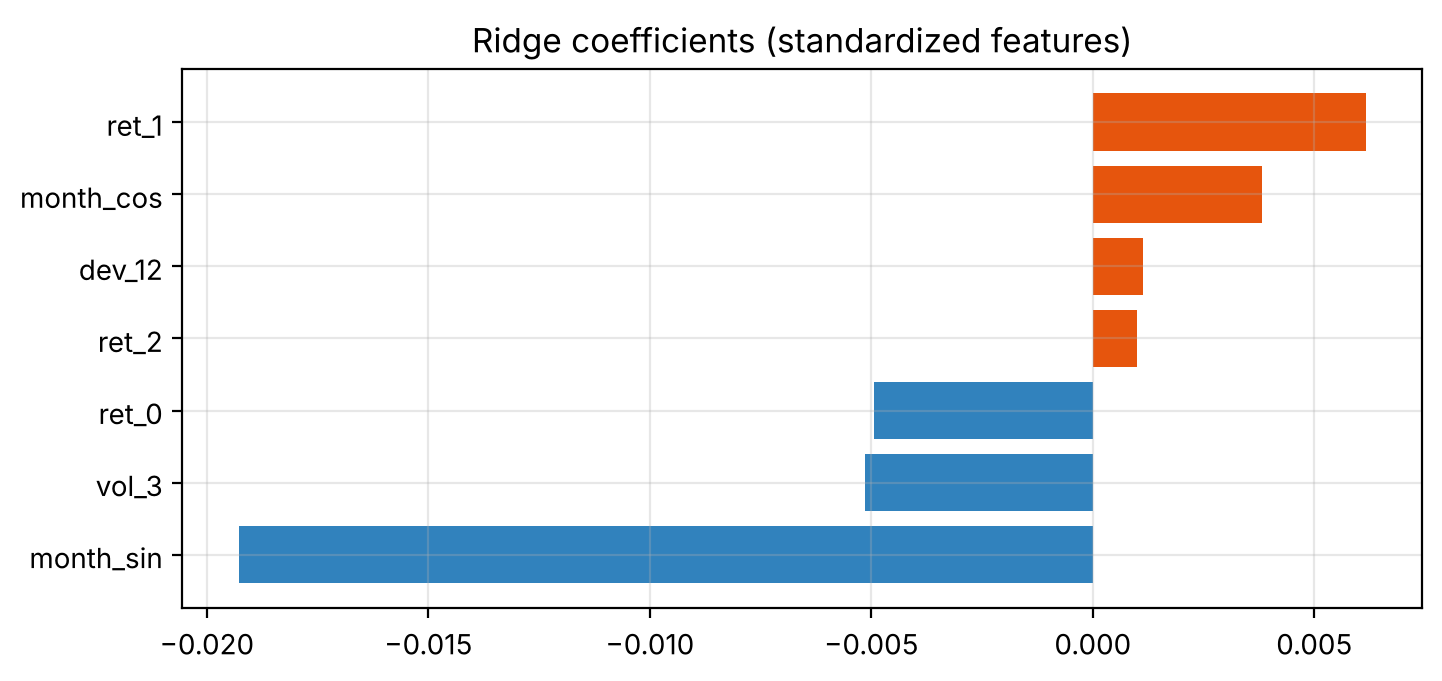

feature ที่ดันราคาเดือนหน้าขึ้นมากที่สุด: ret_1 | ดึงลงมากที่สุด: month_sin


In [ ]:
# 8.5 โมเดลให้น้ำหนักอะไร: สัมประสิทธิ์ของ Ridge (เทรนด้วยข้อมูลก่อนเดือนสุดท้ายของ test)
train = data[data.index < test_idx[-1]].dropna(subset=FEATS + ['target'])
ridge = MODELS['Ridge']().fit(train[FEATS], train['target'])
coef = pd.Series(ridge[-1].coef_, index=FEATS).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(coef.index, coef.values, color=np.where(coef > 0, '#e6550d', '#3182bd'))
ax.set_title('Ridge coefficients (standardized features)'); plt.show()
print('feature ที่ดันราคาเดือนหน้าขึ้นมากที่สุด:', coef.idxmax(), '| ดึงลงมากที่สุด:', coef.idxmin())

## ขั้น 9 · สรุปตัวเลขสำหรับโปสเตอร์ และข้อเสนอแนะ (R6)
cell นี้ print ตัวเลขทั้งหมดที่ใช้บนโปสเตอร์ ถ้ารันใหม่แล้วตัวเลขเปลี่ยน ให้ใช้ตัวเลขจาก cell นี้

In [ ]:
# 9.1 ตัวเลขสำคัญ
print('=== R2 ===')
print(f'ราคา: U.S. Bureau of Labor Statistics, Average Price Data, series {eggs_raw["series_id"].iloc[0]} (https://data.bls.gov/timeseries/APU0000708111, public domain)')
print('      ดาวน์โหลดผ่านชุดรวมบน Kaggle: sadiqguru/us-bls-average-prices')
print(f'ใช้ {len(price)} เดือน ({price.index[0]:%Y-%m} → {price.index[-1]:%Y-%m}) จากไฟล์ดิบ {len(raw):,} แถว | เติมค่าว่าง {len(imputed_months)} เดือน')
print(f'แบ่งตามเวลา: train ก่อน {TEST_START[:7]} (ขยายทุกเดือนแบบ walk-forward) | test {len(test_idx)} เดือน')
print(f'ไข้หวัดนก: USDA APHIS (ExportToCsv), {len(hpai_raw):,} ฟาร์ม ({hp.date.min():%Y-%m-%d} → {hp.date.max():%Y-%m-%d}), ใช้เฉพาะฟาร์มไก่ไข่ {len(egg)} แห่ง')
print(f'แม่ไก่ไข่: USDA NASS Quick Stats ({LAYERS_ITEM}), {len(layers)} เดือน ({layers.index[0]:%Y-%m} → {layers.index[-1]:%Y-%m})')
print('=== R4 ===')
print(f'Naive MAE ${res.loc["Naive","MAE ($/doz)"]} | Ridge MAE ${res.loc["Ridge","MAE ($/doz)"]} (MASE {res.loc["Ridge","MASE"]}) | GBM MAE ${res.loc["GBM","MAE ($/doz)"]} (MASE {res.loc["GBM","MASE"]})')
def verdict(mase):
    mase = float(mase)
    return 'ชนะ baseline' if mase < 0.95 else ('แพ้ baseline' if mase > 1.05 else 'ใกล้เคียง baseline (ต่างไม่ถึง 5%)')
print(f'โมเดลดีสุด: {best} (MASE {res.loc[best,"MASE"]}) → {verdict(res.loc[best,"MASE"])}')
print(f'B ช่วงคัดเลือก {sel_idx[0]:%Y-%m}→{sel_idx[-1]:%Y-%m} ({len(sel_idx)} เดือน): MASE ดีขึ้น {gain} → เลือก {SEL_KEY}')
print(f'B ช่วงประเมิน {full_idx[0]:%Y-%m}→{full_idx[-1]:%Y-%m} ({len(full_idx)} เดือน):')
for k in res_final.index: print(f'   {k:22s} MAE ${res_final.loc[k,"MAE ($/doz)"]}  MASE {res_final.loc[k,"MASE"]}  spike {res_final.loc[k,"Spike recall"]}  false alarm {res_final.loc[k,"False alarms"]}')
print('=== R5 ===')
print(f'ช่วงปกติ vs ผันผวน ({best}): MAE ${seg.loc[best,"MAE normal"]} vs ${seg.loc[best,"MAE volatile"]} | MASE {seg.loc[best,"MASE normal"]} vs {seg.loc[best,"MASE volatile"]}')
print(f'Spike recall ({best}): {res.loc[best,"Spike recall"]}, false alarm {res.loc[best,"False alarms"]} ครั้ง | 10 เดือนที่พลาดหนัก ทายต่ำกว่าจริง {under:.0%}')
print('=== R6 ===')
print(f'ช่วงคลาดเคลื่อน 80% (ปกติ): {band.loc["ช่วงปกติ","P10 (%)"]:+.1f}% ถึง {band.loc["ช่วงปกติ","P90 (%)"]:+.1f}% | (ผันผวน): {band.loc["ช่วงผันผวน","P10 (%)"]:+.1f}% ถึง {band.loc["ช่วงผันผวน","P90 (%)"]:+.1f}%')

=== R2 ===
ราคา: U.S. Bureau of Labor Statistics, Average Price Data, series APU0000708111 (https://data.bls.gov/timeseries/APU0000708111, public domain)
      ดาวน์โหลดผ่านชุดรวมบน Kaggle: sadiqguru/us-bls-average-prices
ใช้ 561 เดือน (1980-01 → 2026-09) จากไฟล์ดิบ 356,549 แถว | เติมค่าว่าง 1 เดือน
แบ่งตามเวลา: train ก่อน 2019-01 (ขยายทุกเดือนแบบ walk-forward) | test 92 เดือน
ไข้หวัดนก: USDA APHIS (ExportToCsv), 2,307 ฟาร์ม (2022-02-08 → 2026-11-10), ใช้เฉพาะฟาร์มไก่ไข่ 171 แห่ง
แม่ไก่ไข่: USDA NASS Quick Stats (CHICKENS, LAYERS, TABLE - INVENTORY, AVG, MEASURED IN HEAD), 217 เดือน (2007-12 → 2025-12)
=== R4 ===
Naive MAE $0.212 | Ridge MAE $0.212 (MASE 1.002) | GBM MAE $0.207 (MASE 0.976)
โมเดลดีสุด: GBM (MASE 0.976) → ใกล้เคียง baseline (ต่างไม่ถึง 5%)
B ช่วงคัดเลือก 2022-06→2024-05 (24 เดือน): MASE ดีขึ้น {'layers': 0.026, 'HPAI': 0.059} → เลือก Ridge + layers + HPAI
B ช่วงประเมิน 2024-06→2026-01 (20 เดือน):
   Naive                  MAE $0.407  MASE 1.0  spike 0/5  false alarm 0
 

### 9.2 ร่างข้อเสนอแนะ (R6) — เติมตัวเลขจาก 9.1
- **ผู้ใช้ควรทำอะไร:** ตั้งงบซื้อไข่เดือนหน้า = ราคาที่ทาย × ปริมาณ และ **เผื่องบสำรองตาม P90** ของช่วงคลาดเคลื่อน ถ้าความผันผวน 6 เดือนล่าสุดสูงกว่าเกณฑ์ (ช่วงผันผวน) ให้เผื่อมากขึ้น หรือพิจารณาซื้อตุน/หาโปรตีนทดแทน
- **ข้อมูลประกอบ (การทดลอง B):** ไข้หวัดนกทำให้โมเดล *เตือน* ราคาพุ่งได้ (ช่วงประเมิน 3/5 เทียบกับ 0/5 ของโมเดลราคาอย่างเดียว) แต่เตือนผิดหลายครั้งและ MAE รวมไม่ดีขึ้น → แนะนำให้ฝ่ายจัดซื้อ **ใช้ราคาที่ทายจากโมเดลราคาอย่างเดียวเป็นตัวตั้งงบ** และใช้ **รายงานไข้หวัดนกในฟาร์มไก่ไข่ (APHIS) เป็นสัญญาณเตือน** ให้เผื่องบตาม P90 หรือซื้อตุน; จำนวนแม่ไก่ไข่ (NASS) ไม่แนะนำ เพราะข้อมูลมาช้า
- **บทเรียนการเลือกตัวแปร:** ชุดที่เลือกจากช่วงคัดเลือก (แม่ไก่ + ไข้หวัดนก) ทำได้ดีในช่วงนั้น แต่แย่ลงในช่วงประเมิน → ข้อมูลวิกฤตมีน้อย (ราคาพุ่งแค่ 5 ครั้งต่อช่วง) การเลือกตัวแปรจึงยังไม่เสถียร ต้องเก็บข้อมูลเพิ่มก่อนนำไปใช้จริง
- **ต้นทุน:** ต้องอัปเดตข้อมูล BLS ทุกเดือน (ฟรี) และเทรนโมเดลใหม่ (ไม่กี่วินาที); ถ้าเผื่องบมากเกินไป เงินจะจมอยู่กับงบสำรองที่ไม่ได้ใช้
- **ข้อจำกัดที่ข้อมูลพิสูจน์ไม่ได้:** โมเดลใช้ราคาย้อนหลังอย่างเดียว จึงทายไม่ได้ว่าราคาจะ *เริ่ม* พุ่งเมื่อไร (เหตุภายนอก เช่น โรคระบาดในฟาร์ม ไม่อยู่ในข้อมูล); ข้อมูลมี ~550 เดือน (< 1,000 แถว) และช่วงวิกฤตมีน้อย; ราคาขายปลีกเฉลี่ยทั้งประเทศอาจต่างจากราคาที่ผู้ซื้อรายใหญ่จ่ายจริง; BLS ประกาศราคาช้า ~2 สัปดาห์

## ขั้น 10 · บันทึกการใช้ AI (R7)
เครื่องมือ: Claude (Claude Code) ใช้เป็นผู้ช่วยวิเคราะห์และเขียนโค้ด กลุ่มเป็นผู้ตัดสินใจและตรวจผลทุกครั้ง

| ครั้งที่ | ถาม AI ว่า | AI ตอบ/ให้อะไร | กลุ่มเปลี่ยนอะไร และเพราะอะไร |
|---|---|---|---|
| 1 | ทำไม Random Forest ทายราคาแบนอยู่ ~$4 ตอนราคาจริงพุ่งถึง $6.2 (ปี 2025) ควรทำยังไงต่อ | RF ทายเกินค่าที่เคยเห็นใน train ไม่ได้ + ราคามีเทรนด์ → ควรทาย % การเปลี่ยนแปลงแทนระดับราคา; พบบั๊ก `shift()`+`dropna()` ลบเดือน 2025-10 ถึง 2026-01 ทิ้ง; แนะนำ walk-forward + MASE | **ทำตาม** เปลี่ยน target เป็น log-return, ใช้ `asfreq`+`interpolate`, เปลี่ยนการประเมินเป็น walk-forward และวัดด้วย MASE เพราะตรวจในข้อมูลแล้วพบว่าเดือน 2025-10 ว่างจริง |
| 2 | ช่วยปรับ notebook ให้ครบ R1–R7 | AI เพิ่มข้อมูลไข้หวัดนก (USDA HPAI) ผ่าน CDC/GitHub mirror มาเป็น feature และทำการทดลองเทียบ "มี/ไม่มี HPAI" | **ไม่ทำตามในตอนแรก → ตัดทิ้ง** เพราะตรวจความน่าเชื่อถือของแหล่งข้อมูลไม่ได้ (mirror บน GitHub ไม่ใช่แหล่งทางการ, ไม่รู้ license) โมเดลหลักจึงใช้แค่ BLS `average_prices` ต่อมาได้ไฟล์ทางการจาก USDA APHIS (ครั้งที่ 5) จึงใส่ไข้หวัดนกกลับเป็น **การทดลอง B แยก** โดยโมเดลหลักยังเป็นราคาอย่างเดียว |
| 3 | ตั้งโจทย์ให้ตรงการใช้งานจริง | AI ร่างผู้ใช้เป็น food bank / โครงการอาหารกลางวัน ใช้ตัดสินใจซื้อตุน | **ปรับ** เป็น "ฝ่ายจัดซื้อเสบียง ตั้งงบซื้อไข่เดือนหน้า" ให้ตรงกับโจทย์ที่กลุ่มตั้งไว้ตั้งแต่แรก และเพิ่มช่วงคลาดเคลื่อน (8.4) เพื่อใช้ตั้งงบสำรอง |
| 4 | ไม่มีข้อมูลไข้หวัดนกทางการที่ย้อนถึงปี 1980 ต้องหายังไง | AI อีกตัวเสนอให้เติมข้อมูลปี 1980–2004 เองจากงานวิจัย; Claude เสนอให้ใช้จำนวนแม่ไก่ไข่รายเดือนจาก USDA NASS Quick Stats แทน | **ไม่เติมข้อมูลเอง** เพราะตรวจสอบไม่ได้; กลุ่มดาวน์โหลด NASS เอง ตรวจว่าครบทุกเดือน (2007-12 → 2025-12) และเห็นแม่ไก่ลดลงช่วงระบาด 2015 และ 2022–2025 จริง จึงใช้เป็นการทดลอง B แยกจากโมเดลหลัก |
| 5 | ขอให้ดาวน์โหลดข้อมูลไข้หวัดนกทั้งหมดจากหน้า APHIS | AI พบว่าแดชบอร์ด USDA มีชีต ExportToCsv จึงดึงเป็น CSV (2,307 ฟาร์ม, 2022-02 → 2026-11) และเทียบกับไฟล์ GitHub เดิม: ตรงกันทั้ง 1,688 แถวในช่วงที่ซ้อนกัน | ใช้ไฟล์ทางการแทนไฟล์ GitHub และจดลิงก์ไว้ใน R2 |
| 6 | ให้เทียบตัวแปรแล้วใช้เฉพาะตัวที่สำคัญ | AI แบ่งช่วงทดสอบเป็นช่วงคัดเลือก/ช่วงประเมิน เลือกชุดได้ Ridge + แม่ไก่ + ไข้หวัดนก แต่ชุดนี้แย่กว่า baseline ในช่วงประเมิน | **ไม่เปลี่ยนชุดตัวแปรย้อนหลัง** ให้ดูดีในช่วงประเมิน เพราะจะเป็นการเลือกจากข้อมูลทดสอบ (โกง) แต่รายงานผลตามจริงและสรุปเป็นข้อจำกัด |
| 7 | รัน notebook ใน VS Code ไม่ได้ (ไม่มี ipykernel) | AI สร้าง `.venv` และลงแพ็กเกจที่ต้องใช้ | ใช้ตามนั้น (ไม่กระทบผลวิเคราะห์) |